# Notebook 07: Uncertainty and the thresholds we choose

**Goal (about 4.5 to 5 hours, in three sessions):** put error bars on the pooled results, find out how much they depend on the choices that produced them, and turn both into the benchmark you will run on every station in week 8. The idea to take away: *a result is the measurement plus the choices that produced it; benchmark both.*

Suggested sessions: sections 1 to 3 (about 1.5 hours); sections 4 to 7 (about 1.5 hours); sections 8 and 9 and the exercises (about 2 hours). Section 13 lists projects for week 8 and after; they are outside this budget.

Why this matters for the research question. The README's two hypotheses, stress and structure, predict the same fast direction at STAR: the regional compression and the 2009 structure both point about NE (`rainier_sws.reference`). So the tests that can separate them are differences *between stations* and changes *with time*, and both compare two uncertain numbers. This lesson builds the uncertainty of each number and a fair way to compare two.

Five sources of uncertainty, from the single measurement outwards:

1. **Formal** error on each measurement (section 1).
2. **Sampling** error on the pooled mean: how much it would move with another set of earthquakes (section 3).
3. **Threshold** sensitivity: what the post-processing cuts and the incidence gate do to N, phi and dt (section 4).
4. **Processing** sensitivity: what moving the pick or the windows does to a measurement (section 6, exercise 2).
5. **Systematic** effects that no resampling sees: the filter band, the 0.02 s dt grid, the component orientation, the velocity model, the clock (sections 2 and 9).

Words in **bold** are defined where they first appear; section 10 collects them. Notebooks 03 to 06 are assumed: the filter bank and the dt grid (03), the grid search and nulls (04), SWSPy (05), the results files, roses and circular statistics (06).

> **Which results.** STAR's results here are the research pipeline's re-run on components rotated to true Z/N/E, with clipped events removed (`paths.station_results_csv("STAR", oriented=True)`); the README's *Known facts* say why and how it differs from the original file. "STAR" below means that re-run, except where a cell says it uses the channels as labelled. RCM and MILD are oriented as their metadata say. The counts printed below are the ones every later number rests on.

In [1]:
# --- setup: make the repo importable and keep figures inline ---
import sys, time
from dataclasses import replace
from pathlib import Path
REPO = Path.cwd().parent if (Path.cwd() / "../rainier_sws").exists() else Path.cwd()
sys.path.insert(0, str(REPO))
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.dates as mdates, matplotlib.ticker as mticker
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
from rainier_sws import paths, data, measure, quality, stats, reference, benchmark
P = benchmark.DEFAULT_PARAMS       # the choices the statistics make: 68% intervals, day blocks, minimum N, null width, ...
print("repo:", REPO)

def plain_ticks(ax, ticks, axis="x"):
    """Label a logarithmic axis with plain numbers (as in notebook 03)."""
    a = ax.xaxis if axis == "x" else ax.yaxis
    a.set_ticks(ticks); a.set_major_formatter(mticker.FormatStrFormatter("%g")); a.set_minor_formatter(mticker.NullFormatter())

BAND_NAMES = {"(1.0, 5.0)": "1-5 Hz", "(5.0, 10.0)": "5-10 Hz"}     # the two bands that matter at STAR (notebook 03)

repo: /Users/mhemmett/Seismology/rainier-sws-tutorials/.claude/worktrees/agent-a69c6e8e51948c2ba


In [2]:
STATIONS = ["STAR", "RCM", "MILD"]
# STAR from the research re-run on true Z/N/E with clipped events removed (oriented=True);
# RCM and MILD are oriented as their metadata say, and their results did not change
res = {s: pd.read_csv(paths.station_results_csv(s, oriented=(s == "STAR"))) for s in STATIONS}
star = res["STAR"]
ok = quality.successful(star)                       # every STAR measurement that returned a phi and a dt
kept = quality.post_filtered(star)                  # the ones that pass the post-processing filter
for df in (ok, kept):
    df["band"] = df.filter_band.map(BAND_NAMES).fillna("other bands")
kept["time"] = benchmark.event_times(kept)
kept["day"] = kept.time.dt.floor(P.block)          # UTC day, as in notebook 03
for s in STATIONS:
    f = quality.funnel(res[s])
    print(f"{s}: {f.attempted} attempted, {f.successful} successful, {f.filtered} pass the post-processing filter")

STAR: 1196 attempted, 659 successful, 194 pass the post-processing filter
RCM: 509 attempted, 274 successful, 32 pass the post-processing filter
MILD: 685 attempted, 107 successful, 24 pass the post-processing filter


## 1. Formal errors: what the pipeline reports

Notebook 04 built the measurement as a **grid search**: for every trial fast direction phi and delay dt, undo that split and measure how far the result is from a single, unsplit wave. That number over the (phi, dt) grid is the **misfit surface**, and its minimum is the measurement. SWSPy (notebook 05) does the same in the **ray frame**: Q and T are the two components across the ray after the LQT rotation of notebook 04, and the misfit is λ2/λ1, the smaller over the larger eigenvalue of the two components' covariance, on a grid of 2 degrees by 0.01 s.

How wide is the valley around the minimum? Silver and Chan (1991) answered with an **F-test**. If the noise is Gaussian, the ratio of a misfit value to the minimum follows an F distribution, so every point with misfit below

$$\lambda_{\text{bound}} = \lambda_{\min}\left(1 + \frac{k}{\nu - k}\,F_{k,\,\nu-k}(1-\alpha)\right)$$

is consistent with the data at confidence 1 − α. Here k = 2 (phi and dt are fitted) and ν is the number of **degrees of freedom**: how many independent numbers the noise really holds. A filtered trace of 70 samples holds far fewer than 70, because neighbouring samples are correlated; SWSPy estimates ν from the spectrum of the transverse trace (Walsh et al., 2013). SWSPy uses α = 0.003, a **99.7 percent** region ("3 sigma"). The **formal errors** `phi_error` and `dt_error` are half the width and half the height of the box around that region.

One more step: SWSPy measures every combination of `n_win` window starts and `n_win` window ends, groups the answers with **DBSCAN** (a clustering method that finds dense groups of points), and reports the window with the smallest errors in the tightest group (Teanby et al., 2004). The cell below re-measures two events, rebuilds the reported window's surface and its F-test region, and checks that the box reproduces the reported errors.

62150662: 35 degrees of freedom; the 99.7% region is misfit <= 1.42 x minimum; half-widths dt 0.01 s, phi 6 deg (reported 0.01 s, 6 deg); rows 2k and 2k+1 identical: True
61504373: 18 degrees of freedom; the 99.7% region is misfit <= 2.06 x minimum; half-widths dt 0.01 s, phi 20 deg (reported 0.01 s, 20 deg); rows 2k and 2k+1 identical: True


Text(0.45, 0.98, 'Misfit surfaces of two STAR events; red: the 99.7% region and the reported error box')

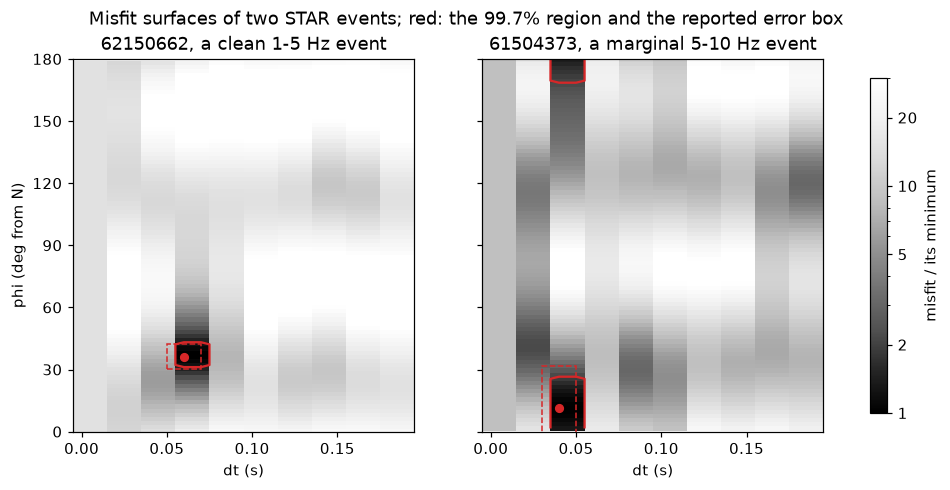

In [3]:
from swspy.splitting import split_windowcheck as swc
cat = data.load_station_catalog("STAR")
lat, lon, _ = data.station_coords("STAR")

def misfit_surface(evid):
    """Re-measure one STAR event and return the misfit surface of the window SWSPy reports, with its 99.7% bound."""
    row = cat[cat.evid == evid].iloc[0]
    m = measure.measure_event(row, data.get_event_stream("STAR", row, allow_download=False), "STAR", lat, lon,
                              incidence_angle=float(star.set_index("evid").loc[evid, "incidence_angle"]))
    so = m.splitting_object
    surf = so.phi_dt_grid_best_window["STAR"]          # lambda2 / lambda1: rows are dt, columns phi (from Q, -90 to 90)
    # the degrees of freedom come from the transverse trace SWSPy used: rotate to the ray frame and cut it the same way
    lqt = swc._rotate_ZNE_to_LQT(m.stream_filtered.copy(), m.back_azimuth, m.incidence_angle)
    s = data.to_utc(row.s_time)
    lqt.trim(s - so.overall_win_start_pre_fast_S_pick, s + so.overall_win_end_post_fast_S_pick + so.max_t_shift_s)
    dof = swc.calc_dof(lqt.select(channel="??T")[0].data)
    bound = swc.ftest(surf, dof, alpha=0.003, k=2)    # the 99.7 percent ("3 sigma") level, as SWSPy uses it
    return dict(m=m, dt=so.lags_labels, phi_Q=so.phis_labels, surf=surf, dof=dof, bound=bound)

def half_widths(s):
    """SWSPy's dt and phi errors: half the extent of the region below the bound (phi wraps at +-90 degrees)."""
    inside = s["surf"] <= s["bound"]
    rows = np.flatnonzero(inside.any(axis=1))
    dt_err = (rows[-1] - rows[0] + 1) * (s["dt"][1] - s["dt"][0]) / 2
    cols = np.flatnonzero(np.hstack([inside.any(axis=0)] * 3))
    phi_err = (inside.shape[1] - (np.diff(cols).max() - 1)) * (s["phi_Q"][1] - s["phi_Q"][0]) / 2
    return dt_err, phi_err

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, evid, what in zip(axes, [62150662, 61504373], ["a clean 1-5 Hz event", "a marginal 5-10 Hz event"]):
    s = misfit_surface(evid); m = s["m"]
    phi_N = np.mod(s["phi_Q"][:-1] + m.back_azimuth, 180)       # phi from north = phi from Q + back azimuth
    order = np.argsort(phi_N)
    z = (s["surf"][:, :-1] / s["surf"].min())[:, order]
    pc = ax.pcolormesh(s["dt"], phi_N[order], z.T, cmap="Greys_r", shading="nearest",
                       norm=plt.matplotlib.colors.LogNorm(vmin=1, vmax=30))
    ax.contour(s["dt"], phi_N[order], (z <= s["bound"] / s["surf"].min()).T.astype(float), levels=[0.5], colors="tab:red", linewidths=1.5)
    ax.add_patch(plt.Rectangle((m.dt - m.dt_error, m.phi % 180 - m.phi_error), 2 * m.dt_error, 2 * m.phi_error,
                               fill=False, ec="tab:red", ls="--", lw=1))
    ax.plot(m.dt, m.phi % 180, "o", color="tab:red", ms=5)
    ax.set(xlabel="dt (s)", title=f"{evid}, {what}", ylim=(0, 180), yticks=range(0, 181, 30))
    ax.grid(False)
    dt_err, phi_err = half_widths(s)
    print(f"{evid}: {s['dof']:.0f} degrees of freedom; the 99.7% region is misfit <= {s['bound'] / s['surf'].min():.2f} x minimum; "
          f"half-widths dt {dt_err:.2f} s, phi {phi_err:.0f} deg (reported {m.dt_error:.2f} s, {m.phi_error:.0f} deg); "
          f"rows 2k and 2k+1 identical: {np.allclose(s['surf'][0::2], s['surf'][1::2])}")
axes[0].set_ylabel("phi (deg from N)")
cb = fig.colorbar(pc, ax=axes, label="misfit / its minimum", shrink=0.9)
cb.set_ticks([1, 2, 5, 10, 20]); cb.ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%g")); cb.ax.yaxis.set_minor_formatter(mticker.NullFormatter())
fig.suptitle("Misfit surfaces of two STAR events; red: the 99.7% region and the reported error box", x=0.45)

Read the two panels (dark: low misfit):

- The bound is a *ratio*. The 99.7 percent region is every point below 1.42 times the minimum for the clean event (35 degrees of freedom) and 2.06 times for the marginal one (18). It depends on the shape of the surface and on ν, not on how strong the noise is.
- The dt axis is labelled every 0.01 s, but its rows come in identical pairs (printed `True`): SWSPy shifts each component by half the trial delay, rounded down to whole samples, so only even numbers of samples are tried (notebook 03, section 8). The smallest region is one pair of rows, which is why dt_error bottoms out at 0.01 s; both events report it. SWSPy reports the first row of the pair, so the dashed box sits half a row to the left of the red region.
- The rebuilt half-widths equal the reported errors (dt 0.01 s for both; phi 6 and 20 degrees), so this *is* what `phi_error` and `dt_error` mean. The marginal event's region is a long thin strip: its dt is sharp, but phi is only pinned to ±20 degrees, and the region wraps from 0 to 180 degrees.

If the formal errors were a noise error bar, they would shrink as the SNR grows. Here they are for every successful STAR measurement.

phi_error: rank correlation with SNR +0.03 (p = 0.47), N = 659
dt_error: rank correlation with SNR +0.05 (p = 0.23), N = 659
dt_error at its floor of 0.01 s: 321; phi_error of 89 degrees or more (the region fills the grid): 62


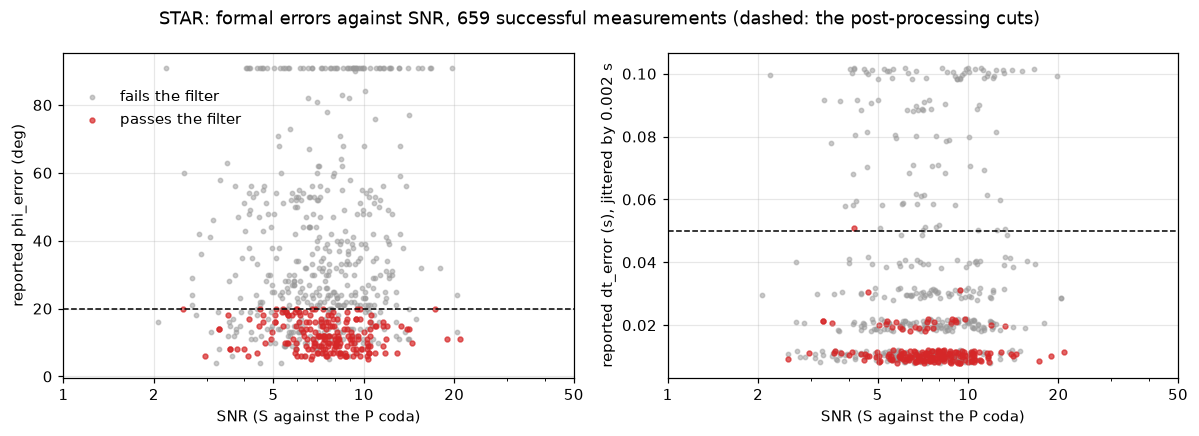

In [4]:
passes = quality.post_filter_mask(ok)
jitter = np.random.default_rng(0).uniform(-0.002, 0.002, len(ok))      # dt_error takes a few values: spread them a little
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, cut, unit, y in [(axes[0], "phi_error", quality.DEFAULT_POST.phi_error_max, "deg", ok.phi_error),
                              (axes[1], "dt_error", quality.DEFAULT_POST.dt_error_max, "s", ok.dt_error + jitter)]:
    ax.scatter(ok.snr_horizontal[~passes], y[~passes], s=8, color="0.6", alpha=0.5, label="fails the filter")
    ax.scatter(ok.snr_horizontal[passes], y[passes], s=10, color="tab:red", alpha=0.7, label="passes the filter")
    ax.axhline(cut, color="k", ls="--", lw=1)
    ax.set(xscale="log", xlabel="SNR (S against the P coda)", ylabel=f"reported {col} ({unit})")
    plain_ticks(ax, [1, 2, 5, 10, 20, 50])
axes[1].set_ylabel("reported dt_error (s), jittered by 0.002 s")
axes[0].legend(frameon=False, loc="upper left", bbox_to_anchor=(0.0, 0.93))      # the low-SNR corner is empty
fig.suptitle(f"STAR: formal errors against SNR, {len(ok)} successful measurements (dashed: the post-processing cuts)")
plt.tight_layout()

from scipy.stats import spearmanr
for col in ("phi_error", "dt_error"):
    rho, p = spearmanr(ok.snr_horizontal, ok[col])
    print(f"{col}: rank correlation with SNR {rho:+.2f} (p = {p:.2f}), N = {len(ok)}")
print(f"dt_error at its floor of {ok.dt_error.min():g} s: {(ok.dt_error == ok.dt_error.min()).sum()}; "
      f"phi_error of 89 degrees or more (the region fills the grid): {(ok.phi_error >= 89).sum()}")

They do not shrink: the rank correlations with SNR are +0.03 and +0.05, indistinguishable from zero. That follows from the construction: the bound is a multiple of the minimum, the degrees of freedom are set mostly by the filter band and the window length, and the grid sets a floor (dt_error 0.01 s for 321 of the 659) and a ceiling (phi_error near 90 degrees, when the region fills the grid, for 62). Many low-SNR measurements have *small* reported errors: a narrow valley in a noisy surface. That is why the pipeline also requires SNR and Q_w.

Two things to carry forward. The reported errors are 3-sigma half-widths, so a third of them is the "one standard error" a statistician would expect. And whether they are right at all is a calibration question, the second project of section 13.

## 2. What dt can be: the filter band and the 0.02 s grid

Notebook 03 established two facts that shape every dt statistic in this lesson. The pipeline chooses a **filter band** for each event (the one with the best SNR), and the **band mix**, the share of events in each band, changes during the swarm (notebook 03, exercise 3). And SWSPy's dt comes in steps of 0.02 s at 100 Hz (`measure.dt_step`; section 1 showed why), so dt is a count of steps, not a continuous number. Here are STAR's filtered dt values, split by band.

filtered events at each dt value:
dt           0.02  0.04  0.06  0.08
band                               
1-5 Hz          5     4   108    19
5-10 Hz        28     3     0     0
other bands    10     5     8     4

per band (benchmark.band_table):
               N  share  mean_phi      R  median_dt  mean_dt  mean_pct  median_pct
band                                                                              
(1.0, 5.0)   136  0.701    32.330  0.897       0.06    0.061     3.415       3.330
(5.0, 10.0)   31  0.160    39.690  0.887       0.02    0.022     1.236       1.128
(3.0, 5.0)    10  0.052    18.183  0.801       0.06    0.058     3.135       3.187
(2.0, 8.0)     9  0.046    50.419  0.690       0.02    0.038     2.064       1.474


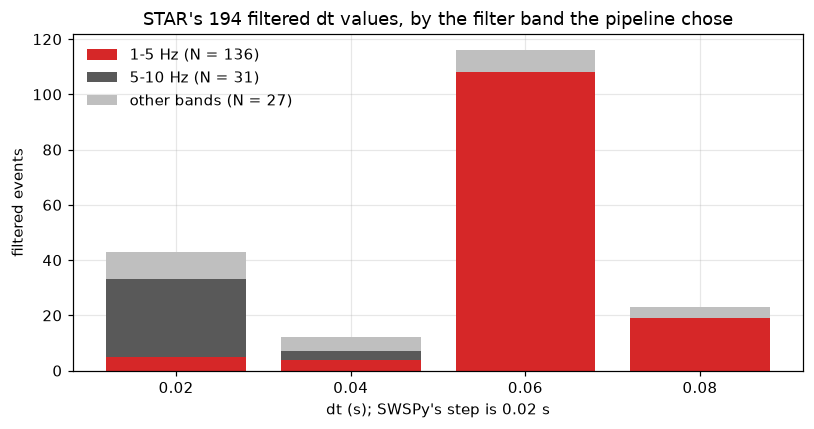

In [5]:
step = measure.dt_step(P.sampling_rate_hz)
grid = np.round(np.arange(step, kept.dt.max() + step / 2, step), 2)
counts = pd.crosstab(kept.band, kept.dt.round(2)).reindex(columns=grid, fill_value=0)
fig, ax = plt.subplots(figsize=(7.5, 4))
bottom = np.zeros(len(grid))
for band, color in [("1-5 Hz", "tab:red"), ("5-10 Hz", "0.35"), ("other bands", "0.75")]:
    ax.bar(grid, counts.loc[band], width=0.8 * step, bottom=bottom, color=color, label=f"{band} (N = {counts.loc[band].sum()})")
    bottom += counts.loc[band].to_numpy()
ax.set(xticks=grid, xlabel=f"dt (s); SWSPy's step is {step:g} s", ylabel="filtered events",
       title=f"STAR's {len(kept)} filtered dt values, by the filter band the pipeline chose")
ax.legend(frameon=False); ax.set_axisbelow(True)
plt.tight_layout()
print("filtered events at each dt value:"); print(counts.to_string())
bands = benchmark.band_table(kept, P)
print("\nper band (benchmark.band_table):"); print(bands.head(4).round(3).to_string())

- **dt is mostly a label of the band.** 108 of the 136 events filtered at 1-5 Hz have dt 0.06 s, and 28 of the 31 at 5-10 Hz have 0.02 s. Only four values occur at all.
- **So is percent anisotropy**, which is 100 × dt over the ray-traced S travel time (notebook 06, section 8). The travel times hardly differ between the bands, so the mean is 3.4 percent at 1-5 Hz and 1.2 at 5-10 Hz. "STAR's percent anisotropy is about 3" is an average over a band mix.
- **phi much less so**: 32 and 40 degrees in the two bands, both tightly clustered (R 0.90 and 0.89). Whether those differ by more than chance is part of exercise 5.

Whether the band difference in dt is physics (splitting that depends on frequency; notebook 03, section 8) or method (what each band can resolve) is exercise 5. Either way, the rules for the rest of this lesson: give dt as a median together with its grid step, give dt and percent anisotropy per band, and compare dt only within one band.

## 3. Sampling error: bootstrap intervals, and how many independent events

Notebook 06 (section 5) introduced the **axial** statistics a fast direction needs, because phi and phi + 180 are the same axis: the axial mean, the mean resultant length **R** (0 for no preferred axis, 1 for all alike), the **circular standard deviation** (the spread of single measurements) and the **Rayleigh test**'s p-value (how likely an R this large would be if the axes were scattered at random). What it left open is how certain the *mean* is.

With one sample of earthquakes we cannot rerun the swarm, so we **bootstrap**: draw N events from the N we have, with replacement, compute the mean, and repeat a thousand times. The spread of those means is the **sampling error**, how much the mean would move with another sample of the same size from the same population. We report the **68 percent interval** of the bootstrap means (16th to 84th percentile), the counterpart of ±1 standard error for a normal distribution and the convention in these lessons (`BenchmarkParams.ci`). Percent anisotropy is reported the same way, as the mean with its 68 percent interval, with the median alongside because its distribution is lumpy (section 2).

`benchmark.pooled_summary` computes all of these. The table gives two intervals for the mean fast direction, one from resampling events and one from resampling days; the next subsection explains the second.

In [6]:
summary = pd.DataFrame({s: benchmark.pooled_summary(quality.post_filtered(res[s]), P) for s in STATIONS}).T
cols = {"N": "N", "mean_phi": "mean phi", "phi_lo": "68% events -", "phi_hi": "68% events +", "phi_block_lo": "68% days -",
        "phi_block_hi": "68% days +", "R": "R", "circ_sd": "circ. SD", "rayleigh_p": "Rayleigh p", "median_dt": "median dt",
        "pct_mean": "% aniso. mean", "pct_lo": "68% -", "pct_hi": "68% +", "pct_median": "% aniso. median"}
summary[list(cols)].astype(float).rename(columns=cols).round(3)

,N,mean phi,68% events -,68% events +,68% days -,68% days +,R,circ. SD,Rayleigh p,median dt,% aniso. mean,68% -,68% +,% aniso. median
STAR,194.0,33.700,-0.874,0.989,-1.804,1.874,0.863,15.581,0.000,0.06,2.930,2.847,3.010,3.250
RCM,32.0,151.182,-3.080,2.809,-3.675,2.707,0.852,16.185,0.000,0.06,3.401,3.195,3.590,3.592
MILD,24.0,110.385,-4.706,6.231,-4.317,18.637,0.420,37.724,0.013,0.04,2.195,2.085,2.321,1.990


How to read it. STAR's mean fast direction is 33.7 degrees, north-north-east, with R 0.86 and a Rayleigh p far below 0.05: a real preferred axis. Its circular standard deviation, 16 degrees, is the spread of single measurements; the interval on the mean is far narrower, and the two answer different questions. RCM has a sixth of STAR's events and an event interval about three times wider. MILD's R of 0.42 means its fast directions are widely spread, so its mean is poorly defined before any interval is drawn, and its day interval is lopsided (−4.3 / +18.6 degrees). Percent anisotropy: STAR 2.93 (68 percent 2.85 to 3.01, median 3.25), RCM 3.40 (3.19 to 3.59, median 3.59), MILD 2.20 (2.09 to 2.32, median 1.99). The medians sit above or below the means because each station's dt takes only a few grid values, and STAR's figure is a band average (section 2).

### Are the events independent?

The bootstrap above treats the 194 events as 194 independent draws. They are not. Swarm earthquakes come in bursts, and a burst is a cluster of nearby sources whose rays share most of their path to STAR: on a busy day the same rock is measured many times. If events on one day resemble each other more than events on different days, resampling single events understates the interval. The remedy is the **block bootstrap**: resample whole blocks (here UTC days, `BenchmarkParams.block`) instead of single events, so that each burst stays together (`stats.block_bootstrap_axial_mean`).

mean phi 33.7 deg; standard deviation of the bootstrap means: events 0.95 deg, days 1.79 deg
the busiest day holds 31 events, the 10 days with 5 or more hold 174; effective number of independent events about 54


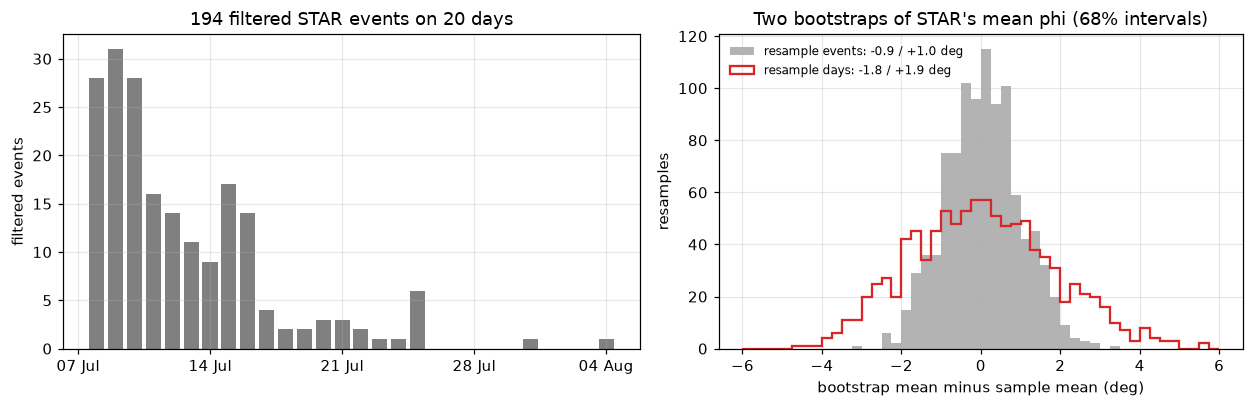

In [7]:
m0, lo, hi, iid = stats.bootstrap_axial_mean(kept.phi, n_boot=P.n_boot, ci=P.ci, seed=P.seed)
_, blo, bhi, by_day = stats.block_bootstrap_axial_mean(kept.phi, kept.day.astype(str), n_boot=P.n_boot, ci=P.ci, seed=P.seed)
per_day = kept.groupby("day").size()
n_eff = len(kept) * (iid.std() / by_day.std()) ** 2           # events that would give the day-block spread if independent

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax0.bar(per_day.index, per_day.values, width=0.8, color="0.5")
ax0.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax0.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0))
ax0.set(ylabel="filtered events", title=f"{len(kept)} filtered STAR events on {len(per_day)} days")
bins = np.linspace(-6, 6, 49)
ax1.hist(iid, bins, color="0.7", label=f"resample events: {lo:+.1f} / {hi:+.1f} deg")
ax1.hist(by_day, bins, histtype="step", color="tab:red", lw=1.5, label=f"resample days: {blo:+.1f} / {bhi:+.1f} deg")
ax1.set(xlabel="bootstrap mean minus sample mean (deg)", ylabel="resamples", title="Two bootstraps of STAR's mean phi (68% intervals)")
ax1.legend(frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
print(f"mean phi {m0:.1f} deg; standard deviation of the bootstrap means: events {iid.std():.2f} deg, days {by_day.std():.2f} deg")
print(f"the busiest day holds {per_day.max()} events, the {(per_day >= P.min_n).sum()} days with {P.min_n} or more hold "
      f"{per_day[per_day >= P.min_n].sum()}; effective number of independent events about {n_eff:.0f}")

Resampling days gives an interval about twice as wide: −1.8 / +1.9 degrees against −0.9 / +1.0 resampling events (standard deviations 1.79 and 0.95 degrees). The square of the ratio of the two spreads says how many *independent* events the 194 are worth: about 54, fewer than the 87 recorded on the first three days alone. That is the number to keep in mind for every comparison in this lesson; exercise 4 asks how it depends on the block length. From here on, intervals on STAR's mean are the day-block ones; the event intervals stay in the tables for comparison.

### The hypotheses in numbers

The README's hypotheses predict fast directions along the regional maximum compression (cracks held open along it) or along the local structure (the 2009 swarm's fault mesh). `rainier_sws.reference` holds both directions; both are approximate.

the two references differ by 0.0 deg
STAR: mean 33.7 deg, 11.3 deg from both references (day-block 68%: -1.8/+1.9); circular SD 16 deg
RCM: mean 151.2 deg, 73.8 deg from both references (day-block 68%: -3.7/+2.7); circular SD 16 deg
MILD: mean 110.4 deg, 65.4 deg from both references (day-block 68%: -4.3/+18.6); circular SD 38 deg


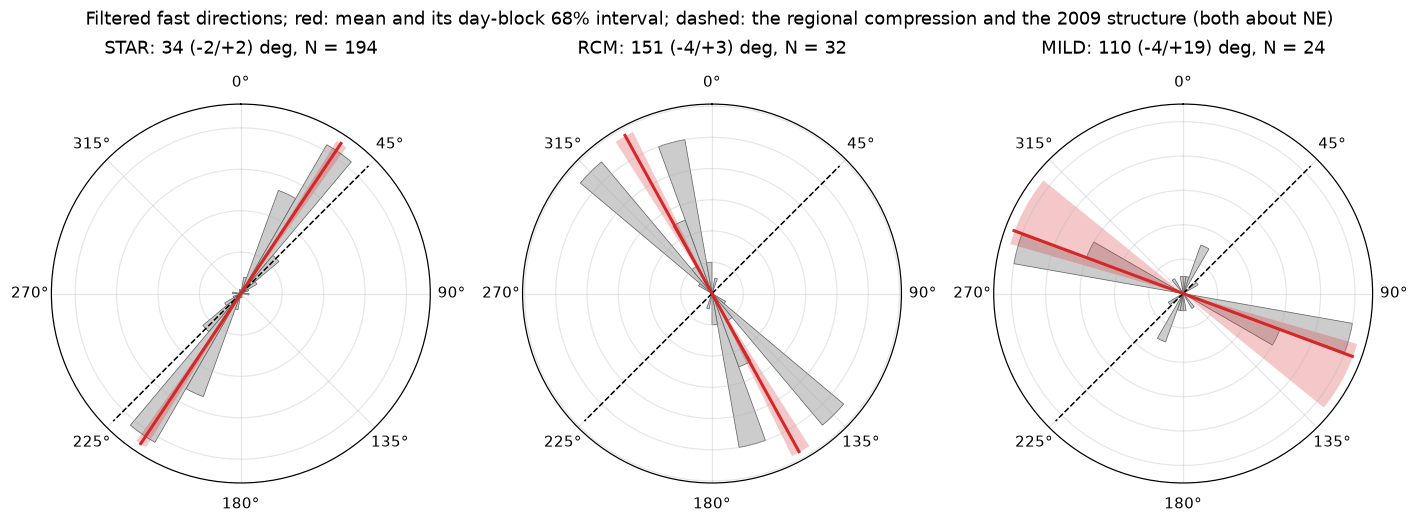

In [8]:
fig = plt.figure(figsize=(13, 4.8))
for i, s in enumerate(STATIONS):
    k_s, r = quality.post_filtered(res[s]), summary.loc[s]
    ax = fig.add_subplot(1, 3, i + 1, projection="polar"); ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    bins_ = np.arange(0, 181, 10); c, _ = np.histogram(measure.phi_0_180(k_s.phi), bins_)
    th = np.deg2rad(np.concatenate([bins_[:-1], bins_[:-1] + 180]))
    ax.bar(th, np.concatenate([c, c]), width=np.deg2rad(10), color="0.8", edgecolor="0.4", lw=0.5, align="edge")
    rmax = ax.get_ylim()[1]
    for base in (0, 180):
        ax.plot([np.deg2rad(reference.REGIONAL_COMPRESSION_AZ + base)] * 2, [0, rmax], "k--", lw=1)
        ax.plot([np.deg2rad(r.mean_phi + base)] * 2, [0, rmax], color="tab:red", lw=2)
        wedge = np.deg2rad(np.linspace(r.mean_phi + r.phi_block_lo + base, r.mean_phi + r.phi_block_hi + base, 20))
        ax.fill_between(wedge, 0, rmax, color="tab:red", alpha=0.25, lw=0)
    ax.set_yticklabels([])
    ax.set_title(f"{s}: {r.mean_phi:.0f} ({r.phi_block_lo:+.0f}/{r.phi_block_hi:+.0f}) deg, N = {int(r.N)}", pad=14)
fig.suptitle("Filtered fast directions; red: mean and its day-block 68% interval; dashed: the regional compression "
             "and the 2009 structure (both about NE)", y=0.98)
plt.tight_layout()
refs = {"regional compression": reference.REGIONAL_COMPRESSION_AZ, "2009 structure": reference.STRUCTURE_2009_STRIKE}
print("the two references differ by", stats.axial_diff(*refs.values()), "deg")
for s in STATIONS:
    r = summary.loc[s]
    print(f"{s}: mean {r.mean_phi:.1f} deg, {stats.axial_diff(r.mean_phi, refs['regional compression']):.1f} deg from both "
          f"references (day-block 68%: {r.phi_block_lo:+.1f}/{r.phi_block_hi:+.1f}); circular SD {r.circ_sd:.0f} deg")

At STAR the mean is 11.3 degrees from both references, several times its day-block interval, but the references are themselves only "about NE", so that offset says little. The point is the angle *between* the hypotheses, which is 0 degrees. An interval on phi can only discriminate between two predictions that differ by more than the interval; at STAR they do not differ at all, and no amount of STAR data will separate them by azimuth.

What can: the other stations and time. RCM and MILD point 74 and 65 degrees away from both references, many times their intervals; if those directions are sound (section 5 has a warning about MILD), one regional cause cannot explain all three stations. Section 7 asks the time question.

## 4. Thresholds: how much of the answer do the cuts decide?

### 4a. The post-processing filter

Each post-processing cut is a field of `quality.PostFilter`. `benchmark.threshold_sweeps` moves one at a time across the values in `BenchmarkParams.sweeps`, the others staying at their defaults, and records N, mean phi and mean dt. A swing of mean phi can be judged in two ways:

- against the **sampling interval** (section 3): does the threshold change the answer by more than its uncertainty?
- against a **random-subset baseline**: moving one cut gives a set that contains the default set, or is contained in it. Even a cut that removed events at random would move the mean a little, because the set gets smaller. The baseline draws, many times (`n_random`), a random subset of the larger set with the size of the smaller one, and takes the 95th percentile of those swings. A swing beyond it means the cut removes (or admits) events that *differ* from the rest, not just fewer of the same.

qw_min = 0.3 admits 17 more events: their mean phi 55 deg, R 0.56 (the default set: 34 deg, R 0.86)
phi_error_max = 45 admits 87 more events: their mean phi 43 deg, R 0.63 (the default set: 34 deg, R 0.86)

largest swing of mean phi for each threshold, and whether any value goes beyond its random-subset baseline:
                           STAR               RCM      MILD
param                                                      
qw_min         1.0 deg (beyond)          2.2 deg   1.3 deg 
snr_min                0.9 deg           2.7 deg   1.6 deg 
phi_error_max  2.4 deg (beyond)  4.6 deg (beyond)  9.9 deg 
dt_error_max           0.1 deg           1.3 deg   2.4 deg 


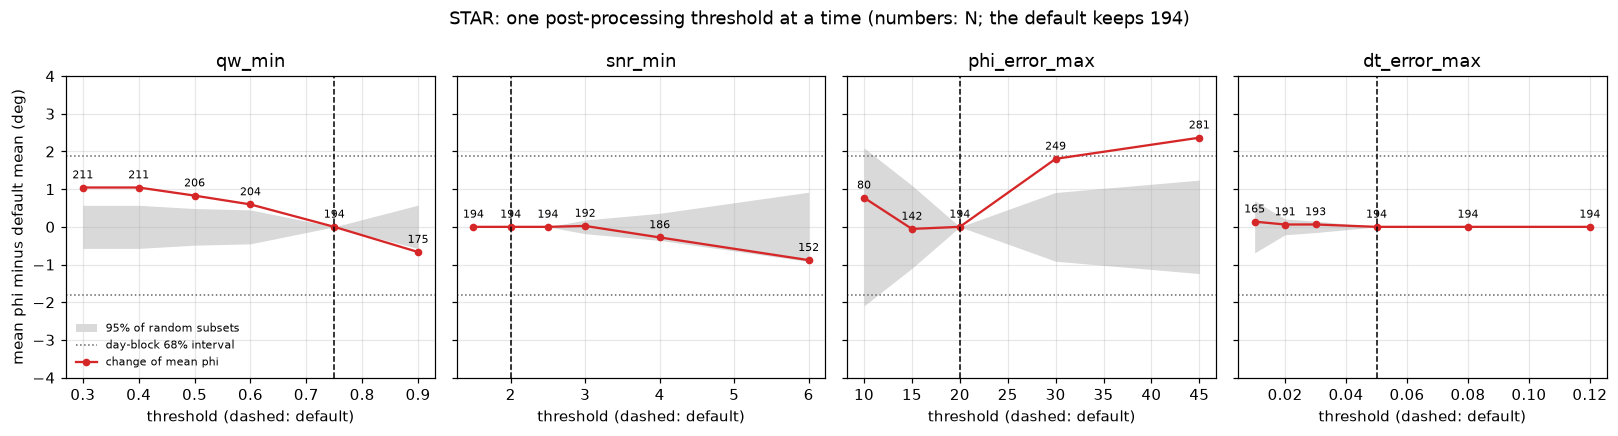

In [9]:
sweeps = {s: benchmark.threshold_sweeps(res[s], quality.DEFAULT_POST, P) for s in STATIONS}
sw = sweeps["STAR"]
m_star = summary.loc["STAR"]
fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=True)
for ax, (param, g) in zip(axes, sw.groupby("param", sort=False)):
    g = g[g.N >= P.min_n]
    change = np.mod(g.mean_phi - m_star.mean_phi + 90, 180) - 90           # signed change of the axial mean
    ax.fill_between(g.value, -g.phi_random, g.phi_random, color="0.85", lw=0, label=f"{P.random_level:.0f}% of random subsets")
    ax.axhline(m_star.phi_block_lo, color="0.4", ls=":", lw=1); ax.axhline(m_star.phi_block_hi, color="0.4", ls=":", lw=1,
                                                                       label="day-block 68% interval")
    ax.plot(g.value, change, "o-", color="tab:red", ms=4, label="change of mean phi")
    ax.axvline(getattr(quality.DEFAULT_POST, param), color="k", ls="--", lw=1)
    for v, c_, n in zip(g.value, change, g.N):
        ax.annotate(str(n), (v, c_), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=7)
    ax.set(title=param, xlabel="threshold (dashed: default)")
axes[0].set(ylabel="mean phi minus default mean (deg)", ylim=(-4, 4))
axes[0].legend(frameon=False, fontsize=7, loc="lower left")
fig.suptitle(f"STAR: one post-processing threshold at a time (numbers: N; the default keeps {int(m_star.N)})")
plt.tight_layout()

kept0 = quality.post_filtered(star)
for param, v in [("qw_min", 0.3), ("phi_error_max", 45)]:
    more = quality.post_filtered(star, replace(quality.DEFAULT_POST, **{param: v}))
    added = more[~more.evid.isin(kept0.evid)]
    print(f"{param} = {v} admits {len(added)} more events: their mean phi {stats.axial_mean(added.phi)[0]:.0f} deg, "
          f"R {stats.axial_mean(added.phi)[1]:.2f} (the default set: {m_star.mean_phi:.0f} deg, R {m_star.R:.2f})")
print("\nlargest swing of mean phi for each threshold, and whether any value goes beyond its random-subset baseline:")
print(pd.DataFrame({s: sweeps[s].groupby("param", sort=False).apply(
    lambda g: f"{g.phi_swing.max():.1f} deg {'(beyond)' if g.beyond_random.any() else ''}", include_groups=False)
    for s in STATIONS}).to_string())

- **Q_w** (Wüstefeld et al., 2010; notebook 04): tightening it to 0.9 drops 19 events and moves the mean 0.7 degrees; loosening it to 0.3 admits 17 and moves it 1.0 degree. Both are beyond the random baseline (0.6 degrees): the 17 events with lower Q_w point 55 degrees on average (printed), a different population.
- **phi_error_max**: loosening it to 30 and 45 degrees admits 55 and 87 events and moves the pooled mean by 1.8 and 2.4 degrees, against baselines of 0.9 and 1.2. The 87 admitted at 45 degrees point 43 degrees on average, with R 0.63: again a different population.
- **snr_min** and **dt_error_max** move the mean no more than random subsets would.

Against the day-block interval (dotted), the largest swing is 2.4 degrees, comparable to the interval itself. So for STAR the honest statement is a mean of about 34 degrees with a couple of degrees from the sample and a couple from the thresholds. RCM and MILD swing more (bottom table), both most with phi_error_max: RCM by up to 4.6 degrees, MILD by up to 9.9. In week 8 these two comparisons, swing against interval and swing against the random baseline, decide whether a station's direction is robust to its thresholds.

### 4b. The pre-processing incidence gate

The pre-gates decide which events are *attempted*. The **incidence angle** is the angle between the ray and the vertical where it reaches the station. Notebook 04 explains the **shear-wave window**: rays steeper than the critical angle, sin⁻¹(Vs/Vp), about 35 degrees for Vp/Vs = 1.73, leave the S wave's particle motion undistorted at the free surface; beyond it the surface reflections make the motion elliptical even in rock without anisotropy, and a splitting measurement reads that as a delay. The pipeline's gate, 45 degrees (`PreGates.incidence_max_deg`), is the usual allowance for slow near-surface rock, which bends rays towards the vertical. The angles come from ray tracing through a velocity model (README), so the gate inherits that model's errors. The rejected events cannot be re-measured here (only STAR's waveforms are cached), but the stored angles answer two cheaper questions: how many events each cutoff would admit, and whether the measured events depend on their angle.

,STAR,RCM,MILD,LON,PANH,OBSR,PARA,RER,COPP
incidence cutoff (deg),,,,,,,,,
30,549,17,1,0,0,0,0,0,0
35,726,93,2,0,0,0,0,0,0
40,825,225,23,0,0,0,0,0,0
45,848,339,134,0,0,2,1,0,0
50,862,424,305,0,0,7,1,0,0
55,872,461,476,0,1,25,2,1,3
60,880,478,581,0,8,52,9,31,13
70,898,487,656,549,268,114,465,322,258


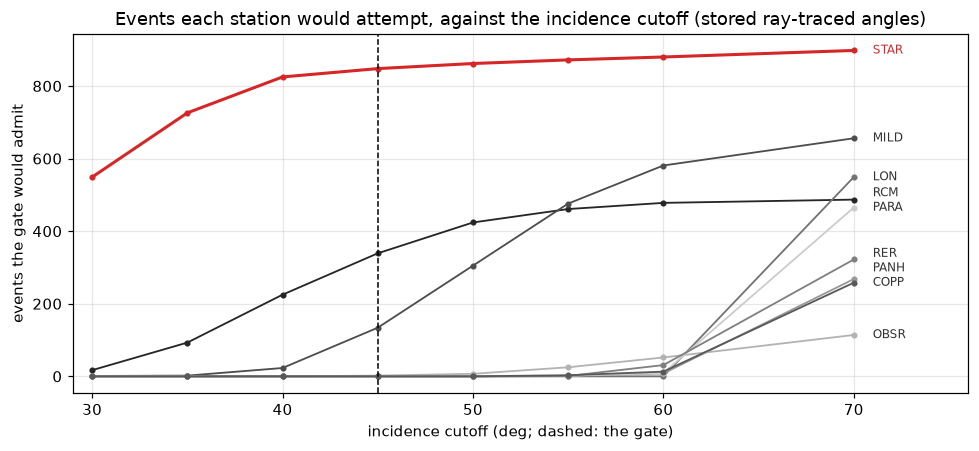

In [10]:
ALL = ["STAR", "RCM", "MILD", "LON", "PANH", "OBSR", "PARA", "RER", "COPP"]
allres = {s: benchmark.load_results(s)[0] for s in ALL}       # STAR: the corrected re-run, as everywhere in this lesson
admit = pd.DataFrame({s: benchmark.incidence_sweep(r, quality.DEFAULT_POST, P).admitted for s, r in allres.items()})
admit.index.name = "incidence cutoff (deg)"
fig, ax = plt.subplots(figsize=(9, 4.2))
greys = iter(["0.15", "0.3", "0.45", "0.6", "0.7", "0.8", "0.5", "0.35"])
for s in ALL:
    ax.plot(admit.index, admit[s], "o-", ms=3, lw=1.2 if s != "STAR" else 2, color="tab:red" if s == "STAR" else next(greys), label=s)
ax.axvline(quality.DEFAULT_PRE.incidence_max_deg, color="k", ls="--", lw=1)
ax.set(xlabel="incidence cutoff (deg; dashed: the gate)", ylabel="events the gate would admit",
       title="Events each station would attempt, against the incidence cutoff (stored ray-traced angles)")
y_label = admit.iloc[-1].sort_values()                        # label each line at its right end, spread apart
for i in range(1, len(y_label)):
    y_label.iloc[i] = max(y_label.iloc[i], y_label.iloc[i - 1] + 40)
for s, y in y_label.items():
    ax.text(admit.index[-1] + 1, y, s, va="center", fontsize=8, color="tab:red" if s == "STAR" else "0.2")
ax.set_xlim(admit.index[0] - 1, admit.index[-1] + 6)
plt.tight_layout()
admit

For PANH, PARA, RER and COPP the count stays near zero until far past 45 degrees: under this velocity model their rays arrive outside the shear-wave window. OBSR is the same with a handful of exceptions, and MILD is borderline (134 admitted at 45 degrees, 305 at 50). LON looks like the worst case, with nothing admitted at any cutoff up to 60 degrees, but it is the exception: the pipeline gated LON on the Jurkevics angle from the P wave, not on these angles (notebook 06, exercise 2), and `benchmark` flags that in its notes. Raising the gate is not a free lunch, because a measurement beyond the window measures the free surface. The question to answer is at what angle recovery degrades, which is a project (section 13).

Among the events that were measured, does the answer depend on the angle?

In [11]:
k_inc = kept.assign(inc_bin=pd.cut(kept.incidence_angle, [0, 20, 30, 40, quality.DEFAULT_PRE.incidence_max_deg]))
def by_bin(g):
    low = g[g.band == "1-5 Hz"]
    return pd.Series({"N": len(g), "mean phi": stats.axial_mean(g.phi)[0], "R": stats.axial_mean(g.phi)[1],
                      "share 1-5 Hz": (g.band == "1-5 Hz").mean(), "mean dt": g.dt.mean(),
                      "N 1-5 Hz": len(low), "mean dt 1-5 Hz": low.dt.mean() if len(low) else np.nan})
k_inc.groupby("inc_bin", observed=True).apply(by_bin, include_groups=False).round(3)

,N,mean phi,R,share 1-5 Hz,mean dt,N 1-5 Hz,mean dt 1-5 Hz
inc_bin,,,,,,,
"(0.0, 20.0]",34.0,33.841,0.914,0.853,0.061,29.0,0.059
"(20.0, 30.0]",122.0,33.441,0.859,0.795,0.055,97.0,0.061
"(30.0, 40.0]",36.0,35.394,0.826,0.250,0.035,9.0,0.062
"(40.0, 45.0]",2.0,19.299,0.998,0.500,0.040,1.0,0.060


The fast direction does not: 33.8, 33.4 and 35.4 degrees in the three populated bins (N = 34, 122 and 36), with R from 0.83 to 0.91. (The last bin has 2 events; ignore it.) The pooled mean dt does fall, from 0.061 to 0.035 s, but the share filtered at 1-5 Hz falls with it, from 0.85 to 0.25, and within 1-5 Hz the mean dt is 0.059 to 0.062 s in every bin. So the trend is the band mix (section 2), not longer paths or different rock.

## 5. Null screening for local earthquakes

A **null** (notebook 04) is a measurement in which the S wave's initial polarization happens to lie along the fast axis or across it: only one of the two waves is excited, nothing is split, and the grid search returns the polarization (or its perpendicular) as "phi" with a meaningless dt. A null screen asks how many fast directions lie close to the initial polarization or its perpendicular.

For the teleseismic SKS phase the initial polarization is the back azimuth, which is why the back azimuth is often used. For a local earthquake it is set by the **focal mechanism**, the orientation of the fault and the direction it slipped, which sends out S waves polarized differently in different directions. SWSPy estimates each event's initial polarization from the waveforms after removing the splitting: `src_pol`, the **source polarization**. The results files do not store it, so the cell re-measures the filtered events (`benchmark.remeasure_filtered`; about 40 s).

The screen flags a fast direction within 20 degrees (`BenchmarkParams.null_width_deg`) of the reference axis or of its perpendicular. That covers 2 × 20 of the 90 possible degrees of separation, so directions scattered at random would be flagged 44 percent of the time (`stats.chance_near_axis`). Every fraction is compared with that.

re-measured 194 events; 193 reproduce phi, dt and Q_w exactly
source polarization: axial mean 53 deg, R 0.68; median SWSPy error 13 deg
near-null against the source polarization: 32; against the back azimuth: 57; both: 5


,N,width_deg,n_near,fraction,chance,mean_phi_all,mean_phi_without,R_without
reference,,,,,,,,
source polarization (null screen),194,20.0,32,0.165,0.444,33.7,33.492,0.863
back azimuth (artifact check),194,20.0,57,0.294,0.444,33.7,35.519,0.947


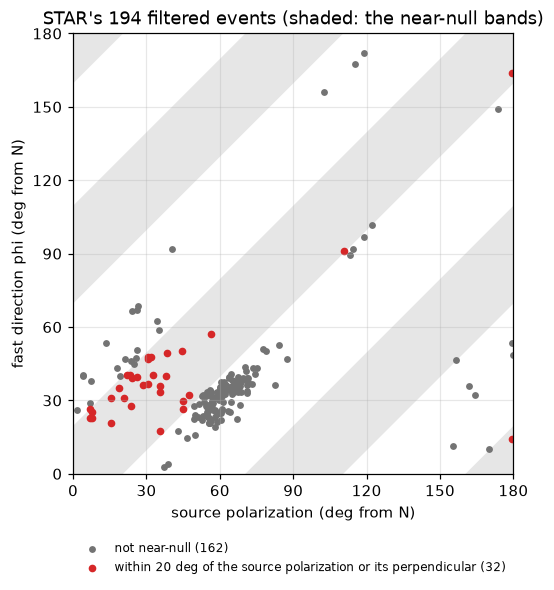

In [12]:
rm = benchmark.remeasure_filtered(star, "STAR")[0.0]      # every filtered event again (about 40 s), for its source polarization
same = np.isclose(rm.phi, kept.phi) & np.isclose(rm.dt, kept.dt) & np.isclose(rm.quality, kept.quality)
print(f"re-measured {len(rm)} events; {same.sum()} reproduce phi, dt and Q_w exactly")
kept["src_pol"] = rm.src_pol
w = P.null_width_deg
near_src = stats.near_axis(kept.phi, kept.src_pol, w)
near_baz = stats.near_axis(kept.phi, kept.back_azimuth, w)
print(f"source polarization: axial mean {stats.axial_mean(kept.src_pol)[0]:.0f} deg, R {stats.axial_mean(kept.src_pol)[1]:.2f}; "
      f"median SWSPy error {rm.src_pol_error.median():.0f} deg")
print(f"near-null against the source polarization: {near_src.sum()}; against the back azimuth: {near_baz.sum()}; both: "
      f"{(near_src & near_baz).sum()}")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
x = np.array([0, 180])
for off in (-180, -90, 0, 90, 180):
    ax.fill_between(x, x + off - w, x + off + w, color="0.9", lw=0)
sp, ph = measure.phi_0_180(kept.src_pol), measure.phi_0_180(kept.phi)
ax.scatter(sp[~near_src], ph[~near_src], s=12, color="0.45", label=f"not near-null ({(~near_src).sum()})")
ax.scatter(sp[near_src], ph[near_src], s=16, color="tab:red", label=f"within {w:g} deg of the source polarization or its perpendicular ({near_src.sum()})")
ax.set(xlim=(0, 180), ylim=(0, 180), xticks=range(0, 181, 30), yticks=range(0, 181, 30), aspect="equal",
       xlabel="source polarization (deg from N)", ylabel="fast direction phi (deg from N)",
       title=f"STAR's {len(kept)} filtered events (shaded: the near-null bands)")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.13))
plt.tight_layout()
screens = pd.DataFrame([benchmark.null_screen(kept.phi, kept.src_pol, "source polarization (null screen)", P),
                        benchmark.null_screen(kept.phi, kept.back_azimuth, "back azimuth (artifact check)", P)])
screens.set_index("reference").round(3)

- 193 of the 194 events reproduce exactly; the measurement is deterministic but can tip between computing environments (README).
- 32 fast directions (16 percent) lie within the near-null bands of their source polarization, far below the 44 percent chance level, and dropping them moves the mean from 33.7 to 33.5 degrees. The red points are the events whose polarization happened to fall near the common fast direction (polarizations of 5 to 50 degrees), not a separate group.
- The source polarizations cluster about 53 degrees (R 0.68; SWSPy's median error on them is 13 degrees), about 19 degrees from the fast directions: the main cloud sits just outside the edge of the shaded band. So the fraction will depend strongly on the width, and the real test is whether phi *follows* the polarization (exercise 3).
- Only 5 events are flagged by both references: for a local earthquake the back azimuth and the source polarization are different things.

### The back-azimuth screen as an artifact check

The back-azimuth screen is still worth running, for another reason. Fast directions that keep lining up with the direction the rays come from are the signature of a processing problem, such as components in the wrong order. That is how STAR's channel exchange showed itself; compare the corrected re-run with the file computed on the channels as labelled.

In [13]:
star_archived = pd.read_csv(paths.station_results_csv("STAR"))     # computed on STAR's channels as labelled
rows = []
for name, r in [("STAR", star), ("STAR, channels as labelled", star_archived), ("RCM", res["RCM"]), ("MILD", res["MILD"])]:
    k_s = quality.post_filtered(r)
    rows.append(benchmark.null_screen(k_s.phi, k_s.back_azimuth, name, P))
pd.DataFrame(rows).rename(columns={"reference": "station"}).set_index("station").round(3)

,N,width_deg,n_near,fraction,chance,mean_phi_all,mean_phi_without,R_without
station,,,,,,,,
STAR,194,20.0,57,0.294,0.444,33.700,35.519,0.947
"STAR, channels as labelled",110,20.0,102,0.927,0.444,91.365,42.580,0.427
RCM,32,20.0,15,0.469,0.444,151.182,163.175,0.938
MILD,24,20.0,22,0.917,0.444,110.385,NaN,NaN


Corrected STAR has 29 percent of its fast directions near the back azimuth, below chance; on the channels as labelled it had 93 percent, 0.48 above chance, and that excess was the warning sign. RCM is at chance (47 percent). MILD is the station to worry about: 92 percent, 0.47 above chance, with only 24 events. Its fast directions run along its rays, which is what an artifact looks like, so MILD's components deserve the same check STAR's got before its direction is used (section 13). Report each fraction with its width, its chance level and N.

## 6. Processing sensitivity on one event

Finally, the knobs inside a single measurement. Re-measure the **figure-3 event** (61504668, the event in figure 3 of the preliminary results, reproduced in notebook 05) with the S pick shifted, with more or fewer windows, and with wider time-shift and pick-uncertainty limits. The knobs are fields of `measure.SwsParams`: `n_win`, the number of window starts and of window ends SWSPy tries (n_win × n_win windows); `max_t_shift_s`, the largest dt searched; and `s_pick_uncertainty`, how far around the pick the windows may start. Each run takes well under a second; the first takes a few seconds while **numba**, the compiler SWSPy uses for its grid search, compiles it.

In [14]:
cat = data.load_station_catalog("STAR")
row = cat[cat.evid == 61504668].iloc[0]
ev = data.get_event_stream("STAR", row, allow_download=False)
lat, lon, _ = data.station_coords("STAR")
inc = float(res["STAR"].set_index("evid").loc[61504668, "incidence_angle"])

def run(label, row=row, params=measure.SwsParams()):
    m = measure.measure_event(row, ev, "STAR", lat, lon, incidence_angle=inc, params=params)
    return {"case": label, "stage": m.stage, "phi": m.phi, "dt": m.dt, "phi_err": m.phi_error, "dt_err": m.dt_error, "Q_w": m.quality}

cases = [run("baseline")]
for shift in (-0.03, +0.03):
    r2 = row.copy(); r2["s_time"] = row.s_time + pd.Timedelta(seconds=shift)
    cases.append(run(f"S pick {shift:+.2f} s", row=r2))
cases.append(run("n_win = 3", params=measure.SwsParams(n_win=3)))
cases.append(run("n_win = 11", params=measure.SwsParams(n_win=11)))
cases.append(run("max_t_shift = 0.1 s", params=measure.SwsParams(max_t_shift_s=0.1)))
cases.append(run("s_pick_uncertainty = 0.06", params=measure.SwsParams(s_pick_uncertainty=0.06)))
pd.DataFrame(cases).set_index("case").round(3)

,stage,phi,dt,phi_err,dt_err,Q_w
case,,,,,,
baseline,ok,-84.783,0.02,11.0,0.01,-0.272
S pick -0.03 s,ok,37.217,0.02,12.0,0.01,1.000
S pick +0.03 s,ok,35.217,0.02,10.0,0.01,0.497
n_win = 3,fail_no_result,NaN,NaN,NaN,NaN,NaN
n_win = 11,ok,-84.783,0.02,11.0,0.01,-0.272
max_t_shift = 0.1 s,ok,35.217,0.02,14.0,0.01,0.969
s_pick_uncertainty = 0.06,ok,35.217,0.02,11.0,0.01,0.969


Read this table carefully; it is more interesting than it looks.

- **dt does not move**: 0.02 s in every case that gives an answer.
- **phi has two answers.** The baseline, and `n_win = 11`, give 95 degrees (east-west, 6 degrees from the back azimuth) with Q_w −0.27, which in the scheme of Wüstefeld et al. (2010) leans towards a null. Shifting the S pick 0.03 s either way, allowing a 0.1 s time shift or widening `s_pick_uncertainty` gives 35 to 37 degrees instead (north-north-east, like most corrected STAR events), with Q_w from 0.50 to 1.0 (all but the 0.50 above the 0.75 cut). Whether this event enters the rose, and with which fast direction, depends on a three-sample pick shift or a window parameter, not on the data.
- `n_win = 3` fails outright: 9 windows, and the DBSCAN step (section 1) needs at least `cluster_min_samples` (15) agreeing ones. A parameter can be *incompatible* with another, not just worse.

One event's place in the result can hinge on a knob nobody thinks about. Exercise 2 repeats this for a marginal event and then for every filtered event.

## 7. Time: does anisotropy change during the swarm?

The research question asks whether the fracture network changes during a swarm, and notebook 06 (section 9) left the test here because it needs everything above. Three traps lie between a plot of phi and dt against time and an answer:

1. **The band mix** (section 2): the share of 1-5 Hz events changes through the swarm, and dt depends on the band. Compare dt within one band.
2. **Clustering** (section 3): events on one day are not independent, so a test that treats them as independent is overconfident.
3. **Where the earthquakes are**: the swarm moved (notebook 02), so a change at one station can be a change of path rather than of the rock. One station cannot tell those apart; more stations and the nodes can.

The figure shows each day with at least `min_n` filtered events: the day's mean fast direction and mean dt (1-5 Hz events and the rest separately), each with a 68 percent bootstrap interval, and the share of the day's events at 1-5 Hz.

day             08 Jul  09 Jul  10 Jul  11 Jul  12 Jul  13 Jul  14 Jul  15 Jul  16 Jul  25 Jul
N               28.000  31.000  28.000  16.000  14.000  11.000   9.000  17.000  14.000   6.000
mean phi        43.203  29.504  37.777  33.924  31.835  25.426  28.036  27.526  29.939  40.690
mean dt 1-5 Hz   0.062   0.056   0.058   0.062   0.060   0.063   0.068   0.060   0.067   0.053
share 1-5 Hz     0.286   0.839   0.607   0.750   0.786   0.545   0.889   0.765   0.857   1.000
daily means for 10 of 20 days, holding 174 of 194 events; 2 later events are off the axis


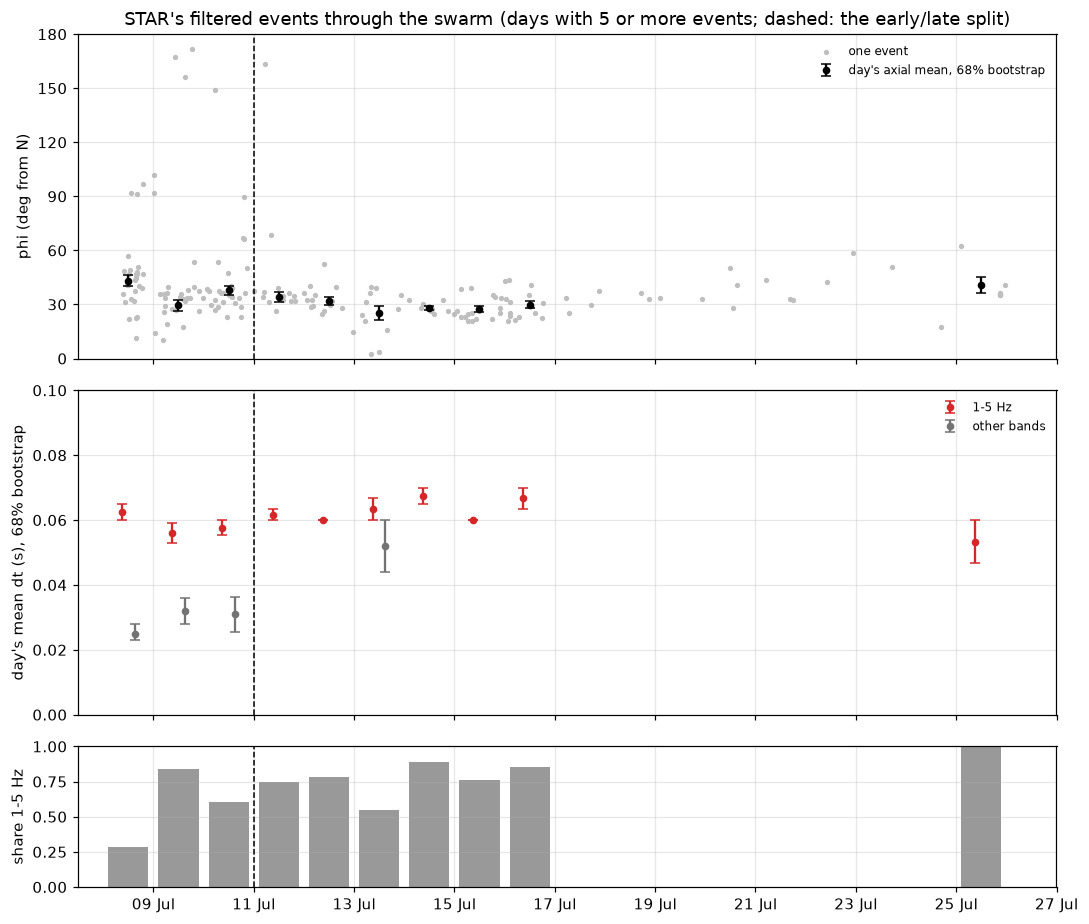

In [15]:
split = pd.Timestamp(P.split_time, tz="UTC")
big_days = kept.groupby("day").size().loc[lambda n: n >= P.min_n].index

def daily(values, axial):
    """Mean of one day's events with its 68% bootstrap interval (axial for phi)."""
    if axial:
        m, lo_, hi_, _ = stats.bootstrap_axial_mean(values, n_boot=P.n_boot, ci=P.ci, seed=P.seed)
        return m, -lo_, hi_
    m, lo_, hi_, _ = stats.bootstrap(np.asarray(values), np.mean, n_boot=P.n_boot, ci=P.ci, seed=P.seed)
    return m, m - lo_, hi_ - m

fig, axes = plt.subplots(3, 1, figsize=(10, 8.5), sharex=True, gridspec_kw={"height_ratios": [3, 3, 1.3]})
noon = pd.Timedelta(hours=12)
axes[0].scatter(kept.time, measure.phi_0_180(kept.phi), s=6, color="0.75", label="one event")
for d in big_days:
    m, e0, e1 = daily(kept.phi[kept.day == d], True)
    axes[0].errorbar(d + noon, m, yerr=[[e0], [e1]], fmt="o", color="k", ms=4, capsize=3,
                     label="day's axial mean, 68% bootstrap" if d == big_days[0] else None)
axes[0].set(ylabel="phi (deg from N)", ylim=(0, 180), yticks=range(0, 181, 30))
for band, color, dx in [("1-5 Hz", "tab:red", -3), ("other bands", "0.45", 3)]:
    sub = kept[kept.band.eq(band) if band == "1-5 Hz" else kept.band.ne("1-5 Hz")]
    days = sub.groupby("day").size().loc[lambda n: n >= P.min_n].index
    for d in days:
        m, e0, e1 = daily(sub.dt[sub.day == d], False)
        axes[1].errorbar(d + noon + pd.Timedelta(hours=dx), m, yerr=[[e0], [e1]], fmt="o", color=color, ms=4, capsize=3,
                         label=band if d == days[0] else None)
axes[1].set(ylabel="day's mean dt (s), 68% bootstrap", ylim=(0, 0.1))
share = kept.groupby("day").band.apply(lambda b: (b == "1-5 Hz").mean()).loc[big_days]
axes[2].bar(share.index + noon, share.values, width=0.8, color="0.6")
axes[2].set(ylabel="share 1-5 Hz", ylim=(0, 1))
for ax in axes:
    ax.axvline(split, color="k", ls="--", lw=1)
for ax in axes[:2]:
    ax.legend(frameon=False, fontsize=8, loc="upper right")
t_end = pd.Timestamp("2025-07-27", tz="UTC")
axes[2].set_xlim(kept.time.min().floor("D") - noon, t_end)
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[0].set_title(f"STAR's filtered events through the swarm (days with {P.min_n} or more events; dashed: the early/late split)")
plt.tight_layout()
low_ = kept[kept.band == "1-5 Hz"]
print(pd.DataFrame({"N": kept.groupby("day").size().loc[big_days],
                    "mean phi": [stats.axial_mean(kept.phi[kept.day == d])[0] for d in big_days],
                    "mean dt 1-5 Hz": low_.groupby("day").dt.mean().reindex(big_days),
                    "share 1-5 Hz": share}).set_index(big_days.strftime("%d %b")).T.round(3).to_string())
print(f"daily means for {len(big_days)} of {kept.day.nunique()} days, holding {kept.day.isin(big_days).sum()} of {len(kept)} events; "
      f"{(kept.time > t_end).sum()} later events are off the axis")

- **phi** moves from day to day by more than the daily intervals: 43 degrees on 8 July, 30 on 9 July, 38 on 10 July, then 25 to 34 degrees on 11 to 16 July (printed).
- **dt** within 1-5 Hz stays between 0.053 and 0.068 s on every day (printed); the other bands sit lower, about 0.03 s on 8 to 10 July (figure). The pooled dt therefore follows the band share (bottom panel), which is lowest on 8 July (0.29).

To test this, split the swarm into its first three days (8 to 10 July UTC, the peak; `BenchmarkParams.split_time`) and the rest, and compare with a **permutation test**: if the split did not matter, the labels "early" and "late" could be shuffled without changing anything, so shuffle them many times and count how often the shuffled difference is at least as large as the real one. That fraction is the **p-value**. The benchmark does it twice: shuffling single events (`stats.permutation_test`), and shuffling whole days (`benchmark.block_permutation_test`), which keeps each day's events together, as the block bootstrap did.

In [16]:
ts = benchmark.time_split(kept, P)
ts.round(4)

,subset,quantity,N_early,N_late,days_early,days_late,early,late,difference,p_event,p_block
0,all bands,phi,87,107,3,17,36.7553,31.6272,5.1281,0.0045,0.3188
1,all bands,dt,87,107,3,17,0.0453,0.0579,0.0127,0.0005,0.0950
2,"(1.0, 5.0) only",phi,51,85,3,15,33.9310,31.5546,2.3764,0.1774,0.4463
3,"(1.0, 5.0) only",dt,51,85,3,15,0.0576,0.0626,0.0049,0.0225,0.2039


Row by row:

- **All bands** (87 early, 107 late): phi differs by 5.1 degrees, p = 0.004 shuffling events but 0.32 shuffling days; dt by 0.013 s, p < 0.001 and 0.10. (With 2000 shuffles the smallest possible p is 0.0005.)
- **1-5 Hz only** (51 early, 85 late): phi differs by 2.4 degrees, p = 0.18 and 0.45; dt by 0.005 s, p = 0.02 and 0.20.

So with STAR alone, **no change of the fast direction or the delay during the swarm stands out from the day-to-day variation** once the band is held fixed and days are the units. The event-level p-values look convincing only because they count the 28 to 31 events of a busy day as independent evidence. The rise of the pooled dt is the band mix; the early phi difference is carried by a few days that also differ from one another.

The day-to-day variation is itself real, larger than the daily intervals. Whether it is the rock changing or the swarm moving onto different paths is exactly the question one station cannot answer. Exercise 1 asks whether the answer depends on where the swarm is split.

## 8. The benchmark

Everything above is now one module, `rainier_sws/benchmark.py`; read it, it is a set of small functions. `benchmark.run(source)` loads a results file (a path, or a station name, for which STAR's corrected re-run is chosen automatically) and returns a `BenchmarkReport`:

| part of the report | field | section |
| --- | --- | --- |
| what was measured: the file, whether it is STAR's corrected re-run, the thresholds, the funnel, the stages | `source`, `oriented`, `post`, `funnel`, `stages` | notebook 06 |
| the pooled answer: N, mean phi with event and day-block 68% intervals, R, circular SD, Rayleigh p, median dt and its step, percent anisotropy (mean, 68% interval, median) | `summary` | 2, 3 |
| what it is made of: each band's N, phi, dt and percent anisotropy | `bands` | 2 |
| whether it could be an artifact: near-null fraction against the back azimuth, and against the source polarization if re-measured | `nulls` | 5 |
| how much the choices matter: threshold sweeps against random subsets; the incidence gate | `sweeps`, `incidence` | 4 |
| whether it changes: early against late, all bands and the main band, p from events and from days | `time_split` | 7 |
| optional: the pick-perturbation test (re-measures; STAR only) | `perturbation` | exercise 2 |
| anything unusual, in words | `notes` | |

Every choice is in `benchmark.BenchmarkParams` (and `quality.PostFilter`): change it there, never as a number in a notebook. `print(report)` gives a text report, `report.row()` one line of the week-8 table, and `benchmark.run_all()` does every file in `results/`. Here is STAR, with the source polarizations of section 5 passed in so they are not measured again.

In [17]:
rep_star = benchmark.benchmark(star, "STAR", source=str(paths.station_results_csv("STAR", oriented=True)), remeasured=rm)
print(rep_star)

== star_strict_oriented: station STAR ==
file: /Users/mhemmett/Seismology/rainier-sws-tutorials/.claude/worktrees/agent-a69c6e8e51948c2ba/results/sws_star_strict_oriented_results.csv  (STAR's re-run on corrected components)
post-processing filter: {'snr_min': 2.0, 'qw_min': 0.75, 'dt_error_max': 0.05, 'phi_error_max': 20.0, 'dt_period_fraction': 0.5}
funnel: attempted 1196, successful 659, filtered 194
stages: ok 659, missing_channel 295, fail_no_result 88, fail_exception 64, fail_incidence 47, fail_clipped 33, fail_snr 9, fail_rectilinearity 1
N = 194: mean phi 33.7 deg, 68% interval -0.9/+1.0 (events), -1.8/+1.9 (20 blocks of D)
R 0.86, circular SD 15.6 deg, Rayleigh p 6.6e-61
dt: median 0.06 s, mean 0.052 s, in steps of 0.02 s (100% on the grid)
percent anisotropy: mean 2.93 (68% 2.85 to 3.01 events, 2.78 to 3.10 days), median 3.25

bands:
                N  share  mean_phi      R  median_dt  mean_dt  mean_pct  median_pct
band                                                         

Every number in this report has appeared above; the report puts them in one place, in the same order for every station. Two lines to look for first: the `note:` lines (empty for STAR) and the two intervals on the mean.

Now four more stations: RCM, MILD and LON, which have measurements, and OBSR, which has none.

In [18]:
reports = [rep_star] + [benchmark.run(s) for s in ["RCM", "MILD", "LON", "OBSR"]]
table = benchmark.summary_table(reports)
show = table[["N", "mean_phi", "phi_68_day", "R", "median_dt", "pct_mean", "pct_68", "pct_median", "main_band", "main_band_share",
              "near_baz", "chance", "near_src_pol", "largest_phi_swing", "swing_from", "beyond_random", "p_day", "notes"]].copy()
for col in ("phi_68_day", "pct_68"):
    show[col] = show[col].apply(lambda t: "" if np.isnan(t[0]) else f"{t[0]:+.1f} / {t[1]:+.1f}" if col == "phi_68_day" else f"{t[0]:.2f}-{t[1]:.2f}")
show.round(3)

,N,mean_phi,phi_68_day,R,median_dt,pct_mean,pct_68,pct_median,main_band,main_band_share,near_baz,chance,near_src_pol,largest_phi_swing,swing_from,beyond_random,p_day,notes
file,,,,,,,,,,,,,,,,,,
star_strict_oriented,194,33.700,-1.8 / +1.9,0.863,0.06,2.930,2.85-3.01,3.250,"(1.0, 5.0)",0.701,0.294,0.444,0.165,2.365,phi_error_max = 45.0,"[phi_error_max, qw_min]",0.319,0
rcm_strict,32,151.182,-3.7 / +2.7,0.852,0.06,3.401,3.19-3.59,3.592,"(1.0, 5.0)",0.656,0.469,0.444,NaN,4.608,phi_error_max = 45.0,[phi_error_max],0.590,0
mild_strict,24,110.385,-4.3 / +18.6,0.420,0.04,2.195,2.09-2.32,1.990,"(1.0, 8.0)",0.458,0.917,0.444,NaN,9.883,phi_error_max = 10.0,[],NaN,1
lon_strict,38,7.431,-3.1 / +3.0,0.652,0.02,0.680,0.61-0.75,0.556,"(5.0, 10.0)",0.237,0.842,0.444,NaN,5.970,phi_error_max = 45.0,[phi_error_max],0.896,1
obsr_strict,0,NaN,,NaN,NaN,NaN,,NaN,NaN,NaN,NaN,0.444,NaN,NaN,NaN,[],NaN,1


In [19]:
for r in reports:
    for n in r.notes:
        print(f"{r.label}: {n}")

mild_strict: early/late split at 2025-07-11: fewer than 5 events on one side
lon_strict: 670 successful measurements have a stored incidence angle above the 45 deg gate: this file was not gated on those angles
obsr_strict: N = 0: no measurement passes the post-processing filter; nothing below is computed


Read the table across, then down.

- **The stations disagree.** STAR 34, RCM 151, MILD 110 and LON 7 degrees, with day-block intervals of a few degrees (MILD's lopsided up to 19): the differences between stations are tens of degrees, far larger than the sampling error. This is the comparison that can separate stress from structure (section 3), *if* each station's measurement is sound.
- **Two stations carry warnings.** MILD's fast directions are 92 percent near-null against its back azimuth (section 5), and its early/late split has too few events on one side to test (the note). LON was gated on a different incidence angle (the note), its median dt is the grid floor of 0.02 s, and its fast directions are 84 percent near-null against its back azimuth.
- **Thresholds.** STAR's largest swing is 2.4 degrees; RCM's, MILD's and LON's are larger (4.6, 9.9 and 6.0), all set by `phi_error_max`.
- **OBSR** says N = 0 and why, instead of a row of silent NaNs.

That table, for every file in `results/`, is the week-8 deliverable (section 13).

## 9. Five sources of uncertainty at STAR

The goal listed five sources of uncertainty. Here they are with their sizes at STAR, computed from the cells above.

In [20]:
b = bands.loc[["(1.0, 5.0)", "(5.0, 10.0)"]]
s_arch = benchmark.pooled_summary(quality.post_filtered(star_archived), P)
sources = pd.DataFrame([
    ("1. formal", "reported per-event errors (99.7% half-widths), median over filtered events",
     f"phi {kept.phi_error.median():.0f} deg, dt {kept.dt_error.median():.2f} s"),
    ("2. sampling", "68% interval of mean phi: events / days",
     f"{m_star.phi_lo:+.1f}/{m_star.phi_hi:+.1f} / {m_star.phi_block_lo:+.1f}/{m_star.phi_block_hi:+.1f} deg"),
    ("3. threshold", "largest swing of mean phi over the post-processing sweeps",
     f"{sw.phi_swing.max():.1f} deg ({sw.loc[sw.phi_swing.idxmax(), 'param']} = {sw.loc[sw.phi_swing.idxmax(), 'value']:g})"),
    ("4. processing", "events whose phi or membership changes when the S pick moves one sample", "exercise 2"),
    ("5. systematic: band", "median dt and mean percent anisotropy, 1-5 Hz against 5-10 Hz",
     f"{b.median_dt.iloc[0]:.2f} vs {b.median_dt.iloc[1]:.2f} s; {b.mean_pct.iloc[0]:.1f} vs {b.mean_pct.iloc[1]:.1f}%"),
    ("5. systematic: grid", "dt comes in steps", f"{step:g} s"),
    ("5. systematic: orientation", "mean phi on the exchanged channels against the corrected ones",
     f"{s_arch.mean_phi:.0f} vs {m_star.mean_phi:.0f} deg"),
    ("5. systematic: velocity model", "which events are attempted (incidence gate)", "section 4b; a project"),
    ("5. systematic: velocity model", "ray-traced travel time over the observed S travel time (percent anisotropy divides by it)",
     "about 1.39 (notebook 06, exercise 4)"),
    ("5. systematic: clock", "STAR's clock may wander by about 100 ms (notebook 04b): moves the windows", "not measured here"),
], columns=["source", "what", "size at STAR"]).set_index("source")
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    print(sources.to_string())

                                                                                                                    what                          size at STAR
source                                                                                                                                                        
1. formal                                     reported per-event errors (99.7% half-widths), median over filtered events                 phi 12 deg, dt 0.01 s
2. sampling                                                                      68% interval of mean phi: events / days             -0.9/+1.0 / -1.8/+1.9 deg
3. threshold                                                   largest swing of mean phi over the post-processing sweeps          2.4 deg (phi_error_max = 45)
4. processing                                    events whose phi or membership changes when the S pick moves one sample                            exercise 2
5. systematic: band                           

For STAR's **direction**, the sampling and threshold terms are each about two degrees, and the largest systematic error found so far, the channel exchange, moved the mean by 58 degrees (91 against 34) before it was fixed. For **dt and percent anisotropy**, the systematic terms dominate: the band changes dt by a factor of three, the grid step is a third of the typical delay, and the velocity model's travel times are about 1.39 times the observed S travel times at STAR (notebook 06, exercise 4), so percent anisotropy computed from them is too low by about that factor if the observed times are right. None of these shows up in a bootstrap. A write-up should give the bootstrap interval *and* name the systematics.

## 10. Glossary

| term | meaning | section |
| --- | --- | --- |
| 68 percent interval | 16th to 84th percentile of bootstrap values; about ±1 standard error | 3 |
| axial statistics | statistics of axes (phi = phi + 180): double the angles, average, halve (notebook 06) | 3 |
| band mix | the share of events in each filter band; it changes during the swarm | 2 |
| block bootstrap | a bootstrap that resamples whole blocks (days) so that clustered events stay together | 3 |
| bootstrap | resample the events with replacement many times to see how much a statistic would vary | 3 |
| circular standard deviation | spread of single axial measurements, in degrees | 3 |
| DBSCAN | clustering method that finds dense groups of points; SWSPy uses it on its windows' answers | 1 |
| degrees of freedom | how many independent numbers a noisy trace holds; fewer than its samples | 1 |
| effective N | the number of independent events that would give the block-bootstrap spread | 3 |
| F-test | test of whether one misfit is significantly larger than the minimum, given the degrees of freedom | 1 |
| figure-3 event | event 61504668, the one in figure 3 of the preliminary results (notebook 05) | 6 |
| filter band | the bandpass the pipeline chose for an event, the one with the best SNR (notebook 03) | 2 |
| focal mechanism | the orientation of an earthquake's fault and its slip; sets the polarization of its S waves | 5 |
| formal error | SWSPy's phi_error and dt_error: half-widths of the 99.7% F-test region | 1 |
| free-surface effect | distortion of S particle motion by the reflections at the surface, beyond the critical angle | 13 |
| grid search | try every (phi, dt) pair on a grid and keep the best one (notebook 04) | 1 |
| incidence angle | angle between the ray and the vertical at the station | 4 |
| misfit surface | the misfit (λ2/λ1 in SWSPy) over the (phi, dt) grid | 1 |
| multiple comparisons | running many tests: some come out "significant" by chance (about 1 in 20 at p < 0.05) | 12 (ex. 1) |
| null | a measurement whose initial polarization lies along or across the fast axis: no split | 5 |
| numba | the compiler SWSPy uses to speed up its grid search | 6 |
| p-value | how often chance alone gives a result at least as extreme as the one observed | 7 |
| permutation test | shuffle group labels many times; the p-value is how often the shuffled difference is as large as the real one | 7 |
| R | mean resultant length of axial data: 0 no preferred axis, 1 all alike | 3 |
| random-subset baseline | the swing of a mean when the same number of events is removed at random | 4 |
| ray frame (Q, T) | the two components across the ray after the LQT rotation (notebook 04) | 1 |
| Rayleigh test | the probability of an R this large from axes scattered at random | 3 |
| sampling error | how much a pooled statistic would move with another sample of the same size | 3 |
| shear-wave window | incidence angles inside which the free surface leaves S undistorted, up to about 35 degrees | 4 |
| source polarization | `src_pol`: SWSPy's estimate of the initial S polarization, deg from N | 5 |
| systematic error | an error that resampling cannot see: band, grid, orientation, velocity model, clock | 9 |
| VT earthquake | volcano-tectonic: an ordinary small earthquake on a fault in the volcano, here the pre-swarm background | 13 |

References in this notebook: Silver, P.G. & Chan, W.W. (1991), *Shear wave splitting and subcontinental mantle deformation*, JGR 96, 16429-16454. Walsh, E., Arnold, R. & Savage, M.K. (2013), *Silver and Chan revisited*, JGR Solid Earth 118, 5500-5515, doi:10.1002/jgrb.50386. Teanby, N.A., Kendall, J.-M. & van der Baan, M. (2004), *Automation of shear-wave splitting measurements using cluster analysis*, BSSA 94, 453-463. Wüstefeld, A., Al-Harrasi, O., Verdon, J.P., Wookey, J. & Kendall, J.-M. (2010), *A strategy for automatic shear-wave splitting analysis and quality control*, Geophys. Prospect. 58, 755-773, doi:10.1111/j.1365-2478.2010.00891.x. Fisher, N.I. (1993), *Statistical Analysis of Circular Data*, Cambridge University Press. Hudson, T.S., Asplet, J. & Walker, A.M. (2023), *Automated shear-wave splitting analysis for single- and multi-layer anisotropic media*, Seismica 2(2). Crampin, S. & Peacock, S. (2008), *A review of the current understanding of seismic shear-wave splitting in the Earth's crust and common fallacies in interpretation*, Wave Motion 45, 675-722.

## 11. Exercises

Each answers a question the project needs. Allow about 20 minutes each; the projects of section 13 are outside this lesson's budget.

1. **Does the time answer depend on where the swarm is split?** Section 7 split at 11 July. Move the split one day at a time from 9 to 17 July (`dataclasses.replace(P, split_time=...)` and `benchmark.time_split`), and tabulate the differences and both p-values for phi and dt, over all bands and within 1-5 Hz. Does any split give a change within one band that survives the day-level test?
2. **Is the filtered set itself robust?** Repeat section 6 for event 61504373, which passes every cut only just: which knob breaks it first? Then scale up: re-measure every filtered event with the S pick moved one sample each way (`benchmark.remeasure_filtered(..., shifts=P.perturb_shifts_s)`, then `benchmark.perturbation_test`; about 80 s). How many events leave the filtered set, how many change phi by more than 20 degrees, and what is the mean of the stable ones? Would a tighter Q_w cut keep only stable events?
3. **Is NNE a polarization artifact?** Recompute the near-null fractions at widths of 10 and 30 degrees for both references and compare them with chance. Then group the events by source polarization in 30-degree bins: if the fast direction were the polarization showing through, it would follow it. Does it?
4. **How many independent events do we have?** Repeat the block bootstrap with blocks of 1, 3, 6, 12, 24 and 48 hours. Where does the interval stop growing, and what effective N does that give? Which threshold swings of section 4 exceed half the day-block interval?
5. **Frequency-dependent splitting, or the method?** For the 1-5 and 5-10 Hz bands, compare the dt values of all successful measurements with those that pass the filter, against the median dominant period T and the cycle-skip limit T/2 (notebook 03, exercise 4). Does the filter's dt ≤ T/2 cut make the 0.02 s at 5-10 Hz? Could a 5-10 Hz measurement report 0.06 s? Is the difference in phi between the two bands (notebook 06, exercise 7) larger than chance? What should a write-up quote as STAR's percent anisotropy?

Then section 13: week 8.

## 12. Example solutions

One way to do each exercise; try them yourself first. Everything uses STAR's corrected re-run and the variables defined above (`kept`, `ok`, `rm`, `sw`, `P`).

### Exercise 1: does the time answer depend on where the swarm is split?

In [21]:
rows = []
for day in pd.date_range("2025-07-09", "2025-07-17", freq="D"):
    t = benchmark.time_split(kept, replace(P, split_time=str(day.date())))
    for _, r in t.iterrows():
        rows.append({"split": day.strftime("%d %b"), "test": f"{r.quantity}, {r.subset}", "N early/late": f"{r.N_early}/{r.N_late}",
                     "difference": r.difference, "p events": r.p_event, "p days": r.p_block})
splits = pd.DataFrame(rows)
cols = ["phi, all bands", "phi, (1.0, 5.0) only", "dt, all bands", "dt, (1.0, 5.0) only"]
for what in ("difference", "p events", "p days"):
    print(f"\n{what}:")
    print(splits.pivot(index="split", columns="test", values=what)[cols].round(3).to_string())
hits = splits[splits["p days"] < 0.05]
print(f"\n{len(hits)} of {len(splits)} tests have p days < 0.05:"); print(hits.round(3).to_string(index=False))


difference:
test    phi, all bands  phi, (1.0, 5.0) only  dt, all bands  dt, (1.0, 5.0) only
split                                                                           
09 Jul          10.947                 5.481          0.019                0.002
10 Jul           3.444                 1.156          0.011                0.004
11 Jul           5.128                 2.376          0.013                0.005
12 Jul           5.018                 2.997          0.011                0.004
13 Jul           4.503                 1.997          0.010                0.005
14 Jul           2.647                 2.162          0.009                0.004
15 Jul           1.463                 1.097          0.007                0.003
16 Jul           1.656                 1.639          0.009                0.004
17 Jul           4.731                 4.364          0.008                0.001

p events:
test    phi, all bands  phi, (1.0, 5.0) only  dt, all bands  dt, (1.0, 5.0) only
spli

**No split survives, once you count the tests.**

- Shuffling single events, the pooled dt "changes" at every split (p from below 0.001 to 0.046) and the pooled phi at the early splits: that is the band mix and the clustering of sections 2 and 3, as before.
- Shuffling days, the all-band p-values are 0.24 to 0.75 for phi and 0.095 to 0.28 for dt, and within 1-5 Hz 0.16 to 0.70 for dt.
- One test falls below 0.05: phi within 1-5 Hz split at 17 July (4.4 degrees, p = 0.034 by days), with only 23 events in its late group.

That last one is the lesson of **multiple comparisons**. This cell ran 36 tests (9 splits × 4 tests); if nothing changed at all, about 36 × 0.05 ≈ 2 of them would still come out below 0.05. One hit among 36, on a small group, is what chance looks like. If a split had been chosen *before* looking (for example from the seismicity, when the swarm moved), its p-value would mean what it says; chosen after scanning nine, it does not.

### Exercise 2: is the filtered set itself robust?

Event 61504373 is marginal on the corrected data: it passes every post-processing cut, but only just, with SNR 2.5 (the cut is 2) and phi_error exactly 20 degrees (the cut is 20). Turn the knobs of section 6, with the pick moved in smaller steps so you can see which breaks it *first*.

In [22]:
MARGINAL = 61504373
row_m = cat[cat.evid == MARGINAL].iloc[0]
ev_m = data.get_event_stream("STAR", row_m, allow_download=False)
inc_m = float(res["STAR"].set_index("evid").loc[MARGINAL, "incidence_angle"])

def run_event(label, ev_, row_, inc_, params=measure.SwsParams()):
    m = measure.measure_event(row_, ev_, "STAR", lat, lon, incidence_angle=inc_, params=params)
    passes = bool(quality.post_filter_mask(pd.DataFrame([m.as_row()])).iloc[0]) if m.stage == "ok" else False
    return {"case": label, "stage": m.stage, "phi": m.phi, "dt": m.dt, "phi_err": m.phi_error,
            "dt_err": m.dt_error, "Q_w": m.quality, "SNR": m.snr_horizontal, "passes filter": passes}

cases = [run_event("baseline", ev_m, row_m, inc_m)]
for shift in (-0.03, -0.02, -0.01, +0.01, +0.02, +0.03):
    r2 = row_m.copy(); r2["s_time"] = row_m.s_time + pd.Timedelta(seconds=shift)
    cases.append(run_event(f"S pick {shift:+.2f} s", ev_m, r2, inc_m))
for n_win in (5, 9, 11):
    cases.append(run_event(f"n_win = {n_win}", ev_m, row_m, inc_m, params=measure.SwsParams(n_win=n_win)))
cases.append(run_event("max_t_shift = 0.1 s", ev_m, row_m, inc_m, params=measure.SwsParams(max_t_shift_s=0.1)))
cases.append(run_event("s_pick_uncertainty = 0.06", ev_m, row_m, inc_m, params=measure.SwsParams(s_pick_uncertainty=0.06)))
print("default n_win:", measure.SwsParams().n_win)
pd.DataFrame(cases).set_index("case").round(3)

default n_win: 7


,stage,phi,dt,phi_err,dt_err,Q_w,SNR,passes filter
case,,,,,,,,
baseline,ok,11.53,0.04,20.0,0.01,0.937,2.510,True
S pick -0.03 s,ok,11.53,0.04,18.0,0.01,0.000,2.287,False
S pick -0.02 s,ok,1.53,0.04,21.0,0.01,0.195,2.291,False
S pick -0.01 s,ok,9.53,0.04,20.0,0.01,0.969,2.329,True
S pick +0.01 s,ok,43.53,0.02,11.0,0.01,0.114,2.657,False
S pick +0.02 s,ok,43.53,0.02,9.0,0.01,0.094,2.601,False
S pick +0.03 s,ok,43.53,0.02,9.0,0.01,0.094,2.477,False
n_win = 5,ok,5.53,0.04,24.0,0.01,0.969,2.510,False
n_win = 9,ok,43.53,0.02,11.0,0.01,0.094,2.510,False


**Which knob breaks it first? The pick.** Of the twelve runs only four pass the filter: the baseline, the pick 0.01 s earlier, 11 windows and a wider `s_pick_uncertainty`. Two kinds of breaking show up:

- **A different answer.** Moving the pick 0.01 to 0.03 s *later*, or using 9 windows, gives phi 44 degrees and dt 0.02 s instead of 12 degrees and 0.04 s, with a *smaller* reported phi error (9 to 11 degrees). Q_w catches it (0.09 to 0.11), so none of those passes.
- **The same answer, rejected.** Moving the pick 0.02 or 0.03 s earlier keeps phi within 10 degrees and dt at 0.04 s, but Q_w drops to 0.20 and 0. With 5 windows or a 0.1 s maximum time shift phi barely moves, but phi_error goes over 20 degrees (24 and 31).

So one sample of pick decides whether this event is in the rose. Section 6's event goes the other way (its baseline fails, its shifted picks pass). How often does this happen across the whole filtered set? Move every pick one sample each way and re-measure.

In [23]:
perturbed = benchmark.remeasure_filtered(star, "STAR", shifts=P.perturb_shifts_s)     # about 80 s
pert = benchmark.perturbation_test(kept, perturbed, quality.DEFAULT_POST, P)
print(pert.to_string())
stable = np.logical_and.reduce([quality.post_filter_mask(m) for m in perturbed.values()])
moved = np.logical_or.reduce([(m.stage == "ok") & (stats.axial_diff(m.phi, kept.phi) > P.moved_deg) for m in perturbed.values()])
stable &= ~moved
print("\nmedians, stable against the rest:")
print(kept.assign(stable=stable).groupby("stable")[["quality", "snr_horizontal", "phi_error"]].median().round(2).to_string())
print("\nshare stable by band:", kept.assign(stable=stable).groupby("band").stable.agg(["size", "mean"]).round(2).to_dict("index"))
for q in (0.9, 0.95, 1.0):
    print(f"share stable among Q_w >= {q}: {stable[kept.quality >= q].mean():.2f} (N = {(kept.quality >= q).sum()})")

N_tested                     194
shifts_s           (-0.01, 0.01)
leave_at_-0.01s               40
leave_at_+0.01s               35
leave_any                     57
moved_any                      7
moved_but_kept                 1
N_stable                     136
mean_phi_stable         33.76229
phi_lo                 -0.778068
phi_hi                   0.92384
R_stable                0.913926

medians, stable against the rest:
        quality  snr_horizontal  phi_error
stable                                    
False      0.97            6.64       15.0
True       0.97            7.85       11.0

share stable by band: {'1-5 Hz': {'size': 136, 'mean': 0.8}, '5-10 Hz': {'size': 31, 'mean': 0.55}, 'other bands': {'size': 27, 'mean': 0.37}}
share stable among Q_w >= 0.9: 0.73 (N = 175)
share stable among Q_w >= 0.95: 0.76 (N = 130)
share stable among Q_w >= 1.0: 0.71 (N = 48)


**Not very.** Moving the pick by one sample removes 40 events (pick earlier) or 35 (later) from the filtered set, 57 of the 194 at one shift or the other, and changes phi by more than 20 degrees for 7 (one of which still passes). The 136 stable events have a mean of 33.8 degrees (event interval −0.8 / +0.9) and R 0.91, against 33.7 and 0.86 for all 194: the direction survives, the membership does not.

Can a cut keep only stable events? Not Q_w: its median is 0.97 for stable and unstable events alike, and the stable share is 0.71 to 0.76 whether Q_w ≥ 0.9, 0.95 or 1.0. The stable events have somewhat higher SNR (median 7.9 against 6.6) and smaller phi_error (11 against 15 degrees), and the band matters most: 80 percent of the 1-5 Hz events are stable, 55 percent of the 5-10 Hz ones and 37 percent of the rest. So the filtered set carries an uncertainty of its own, about 30 percent of its members, that no formal error shows; this is why the perturbation test is part of the benchmark (`benchmark.run("STAR", perturb=True)`).

### Exercise 3: is NNE a polarization artifact?

In [24]:
widths = pd.DataFrame([{"width (deg)": w_, "near source polarization": stats.near_axis(kept.phi, kept.src_pol, w_).mean(),
                        "near back azimuth": stats.near_axis(kept.phi, kept.back_azimuth, w_).mean(),
                        "chance": stats.chance_near_axis(w_)} for w_ in (10, 20, 30)]).set_index("width (deg)")
print(f"near-null fractions, N = {len(kept)}:"); print(widths.round(2).to_string())

# If phi were the polarization showing through, events with different polarizations would give different phi.
kept["src_bin"] = pd.cut(measure.phi_0_180(kept.src_pol), np.arange(0, 181, 30))
print("\nphi by source polarization:")
print(kept.groupby("src_bin", observed=True).phi.agg(N="size", mean_phi=lambda p: stats.axial_mean(p)[0],
                                                     R=lambda p: stats.axial_mean(p)[1]).round(2).to_string())
typical = stats.axial_diff(kept.src_pol, stats.axial_mean(kept.src_pol)[0]) <= 30
d, p = stats.permutation_test(kept.phi[typical], kept.phi[~typical], axial=True, n_perm=P.n_perm, seed=P.seed)
print(f"\nsource polarization within 30 deg of its mean ({typical.sum()}) against the rest ({(~typical).sum()}): "
      f"mean phi {stats.axial_mean(kept.phi[typical])[0]:.1f} vs {stats.axial_mean(kept.phi[~typical])[0]:.1f} deg, "
      f"difference {d:.1f} deg, permutation p = {p:.2f}")

near-null fractions, N = 194:
             near source polarization  near back azimuth  chance
width (deg)                                                     
10                               0.05               0.10    0.22
20                               0.16               0.29    0.44
30                               0.61               0.56    0.67

phi by source polarization:
             N  mean_phi     R
src_bin                       
(0, 30]     30     39.30  0.91
(30, 60]    73     29.93  0.92
(60, 90]    73     35.46  0.98
(90, 120]    7    115.60  0.33
(120, 150]   1    101.65  1.00
(150, 180]  10     23.33  0.63

source polarization within 30 deg of its mean (156) against the rest (38): mean phi 33.6 vs 34.2 deg, difference 0.5 deg, permutation p = 0.82


**No: the fast direction does not follow the polarization.**

- **Width.** Against the source polarization the near-null fraction is 0.05, 0.16 and 0.61 at 10, 20 and 30 degrees, below chance (0.22, 0.44, 0.67) at every width. The jump between 20 and 30 degrees is the main cloud of section 5's figure entering the band: fast directions and polarizations differ by about 20 to 30 degrees for most events. That is a coincidence of two clusters, not a sign of nulls, as the next test shows. Raw fractions depend on the width; always give the width, the chance level and N.
- **Following.** Events polarized at 0 to 30, 30 to 60 and 60 to 90 degrees (N = 30, 73, 73) give fast directions of 39, 30 and 35 degrees, all with R of 0.91 or more: a 60-degree change of polarization leaves phi where it is. The 38 events polarized more than 30 degrees from the typical polarization have a mean of 34.2 degrees against 33.6 for the other 156 (p = 0.82).

The few events polarized at 90 to 120 degrees (7) scatter widely (R 0.33), and those may well be nulls or artifacts, but they are too few to matter. So STAR's north-north-east is not the polarization showing through, which is what the null screen alone could not prove.

### Exercise 4: how many independent events do we have?

           blocks  68% -  68% +  SD (deg)  effective N
block (h)                                             
1             135  -1.00   1.06      1.04       160.61
3              82  -1.14   1.05      1.09       145.39
6              54  -1.32   1.24      1.25       111.22
12             35  -1.44   1.48      1.47        80.87
24             20  -1.80   1.87      1.79        54.05
48             12  -1.66   1.98      1.88        49.33

threshold swings larger than half the day-block interval (1.8 deg):
        param  value   N  phi_swing  phi_random
phi_error_max   45.0 281       2.37        1.24


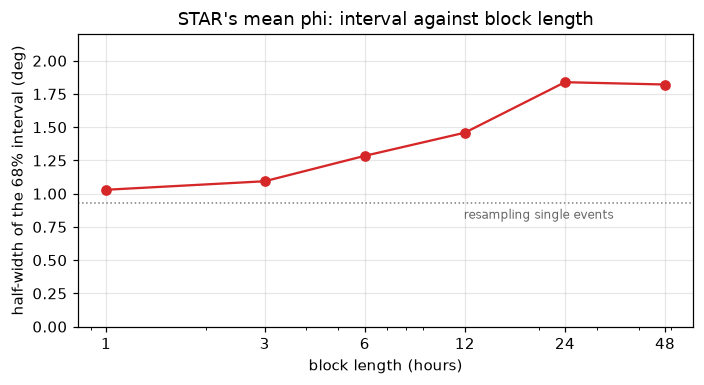

In [25]:
rows = []
for hours in (1, 3, 6, 12, 24, 48):
    blocks = kept.time.dt.floor(f"{hours}h").astype(str)
    _, lo_, hi_, offs = stats.block_bootstrap_axial_mean(kept.phi, blocks, n_boot=P.n_boot, ci=P.ci, seed=P.seed)
    rows.append({"block (h)": hours, "blocks": blocks.nunique(), "68% -": lo_, "68% +": hi_, "SD (deg)": offs.std(),
                 "effective N": len(kept) * (iid.std() / offs.std()) ** 2})
blk = pd.DataFrame(rows).set_index("block (h)")
print(blk.round(2).to_string())
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(blk.index, (blk["68% +"] - blk["68% -"]) / 2, "o-", color="tab:red")
ax.axhline((hi - lo) / 2, color="0.5", ls=":", lw=1); ax.text(20, (hi - lo) / 2 - 0.12, "resampling single events", fontsize=8, color="0.4", ha="center")
ax.set(xscale="log", xlabel="block length (hours)", ylabel="half-width of the 68% interval (deg)", ylim=(0, 2.2),
       title="STAR's mean phi: interval against block length")
plain_ticks(ax, list(blk.index))
plt.tight_layout()
half_day_ = (m_star.phi_block_hi - m_star.phi_block_lo) / 2
print(f"\nthreshold swings larger than half the day-block interval ({half_day_:.1f} deg):")
print(sw[sw.phi_swing > half_day_][["param", "value", "N", "phi_swing", "phi_random"]].round(2).to_string(index=False))

**About 50.** The interval grows with the block length, from a half-width of 1.0 degree with 1-hour blocks to 1.8 with 24-hour blocks, and stops growing there (1.8 with 48-hour blocks). The effective N falls from 161 to 54 and 49. So events within a day are alike, while days are close to independent of each other: a day is the right block, and STAR's 194 filtered events carry about as much independent information as 50 would. Every p-value and interval that treats them as 194 is too confident by about a factor of two in width.

With the day-block interval as the yardstick, one threshold swing exceeds half of it: `phi_error_max` = 45 degrees, 2.4 degrees (and beyond its random baseline of 1.2). The others are within the sampling uncertainty, even where they are beyond the random baseline (Q_w): they select a different population, but one too small to move the answer much.

### Exercise 5: frequency-dependent splitting, or the method?

band                       1-5 Hz  5-10 Hz
successful                383.000  114.000
filtered                  136.000   31.000
median T (s)                0.190    0.115
T/2 (s)                     0.095    0.058
successful at 0.02 s        0.089    0.746
successful at 0.06 s        0.499    0.009
median dt filtered          0.060    0.020
dt / T filtered             0.326    0.177
fail only dt <= T/2         6.000    4.000
mean % aniso. filtered      3.415    1.236
68% -                       3.359    1.178
68% +                       3.477    1.308
median % aniso. filtered    3.330    1.128

phi: 1-5 Hz 32.3 deg (N = 136), 5-10 Hz 39.7 deg (N = 31); difference 7.4 deg, permutation p = 0.0005 (events shuffled between bands; 0.0005 is the smallest possible)
share of each band's events on 8-10 July: 1-5 Hz 0.38, 5-10 Hz 0.68


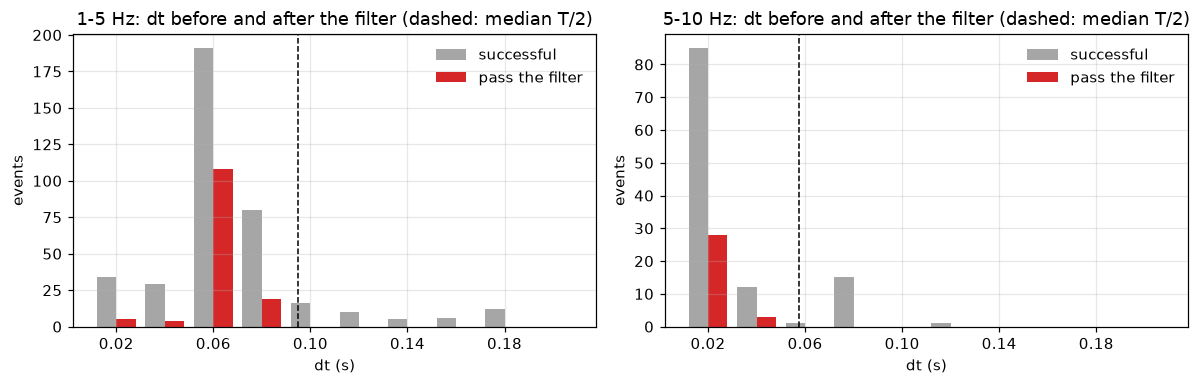

In [26]:
rows = []
for band in ["1-5 Hz", "5-10 Hz"]:
    s_ok, s_kept = ok[ok.band == band], kept[kept.band == band]
    T = s_ok.dominant_period.median()
    rows.append({"band": band, "successful": len(s_ok), "filtered": len(s_kept), "median T (s)": T, "T/2 (s)": T / 2,
                 "successful at 0.02 s": (s_ok.dt.round(2) == 0.02).mean(), "successful at 0.06 s": (s_ok.dt.round(2) == 0.06).mean(),
                 "median dt filtered": s_kept.dt.median(), "dt / T filtered": (s_kept.dt / s_kept.dominant_period).median(),
                 "fail only dt <= T/2": int((quality.post_filter_mask(s_ok, replace(quality.DEFAULT_POST, dt_period_fraction=np.inf))
                                              & ~quality.post_filter_mask(s_ok)).sum()),
                 "mean % aniso. filtered": s_kept.pct_anisotropy.mean(),
                 **dict(zip(["68% -", "68% +"], stats.bootstrap(s_kept.pct_anisotropy.to_numpy(), np.mean, n_boot=P.n_boot,
                                                                ci=P.ci, seed=P.seed)[1:3])),
                 "median % aniso. filtered": s_kept.pct_anisotropy.median()})
print(pd.DataFrame(rows).set_index("band").T.round(3).to_string())

# notebook 06 (exercise 7) found the 5-10 Hz fast directions further east than the 1-5 Hz ones: larger than chance?
low, high = kept.phi[kept.band == "1-5 Hz"], kept.phi[kept.band == "5-10 Hz"]
d, p = stats.permutation_test(low, high, axial=True, n_perm=P.n_perm, seed=P.seed)
print(f"\nphi: 1-5 Hz {stats.axial_mean(low)[0]:.1f} deg (N = {len(low)}), 5-10 Hz {stats.axial_mean(high)[0]:.1f} deg "
      f"(N = {len(high)}); difference {d:.1f} deg, permutation p = {p:.4f} (events shuffled between bands; "
      f"{1 / (P.n_perm + 1):.4f} is the smallest possible)")
early_ = kept.time < pd.Timestamp(P.split_time, tz="UTC")
print(f"share of each band's events on 8-10 July: 1-5 Hz {early_[kept.band == '1-5 Hz'].mean():.2f}, "
      f"5-10 Hz {early_[kept.band == '5-10 Hz'].mean():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
for ax, band in zip(axes, ["1-5 Hz", "5-10 Hz"]):
    s_ok, s_kept = ok[ok.band == band], kept[kept.band == band]
    g = np.round(np.arange(step, 0.2 + step / 2, step), 2)
    ax.bar(g - 0.004, s_ok.dt.round(2).value_counts().reindex(g, fill_value=0), width=0.008, color="0.65", label="successful")
    ax.bar(g + 0.004, s_kept.dt.round(2).value_counts().reindex(g, fill_value=0), width=0.008, color="tab:red", label="pass the filter")
    ax.axvline(s_ok.dominant_period.median() / 2, color="k", ls="--", lw=1)
    ax.set(title=f"{band}: dt before and after the filter (dashed: median T/2)", xlabel="dt (s)", ylabel="events",
           xticks=g[::2])
    ax.legend(frameon=False)
plt.tight_layout()

**The filter does not make the 0.02 s; the method may.**

- At 5-10 Hz, 75 percent of *all* successful measurements already have dt 0.02 s, before any cut, and the dt ≤ T/2 cut removes only 4 events. At 1-5 Hz half the successful measurements have 0.06 s. The difference is in the measurements, not the filter.
- Could a 5-10 Hz measurement report 0.06 s? Barely: the median period there is 0.115 s, so 0.06 s is just past half a period (0.058 s), the cycle-skip limit where a fast wave and an inverted slow wave look alike. Only 1 of the 114 did; 15 reported 0.08 s, beyond the limit, where a delay cannot be told from a cycle skip, and none of those passes the filter. At 1-5 Hz, 0.02 s is a tenth of a period (0.19 s), hard to see. So each band reports delays its periods can resolve (dt/T is 0.33 at 1-5 Hz and 0.18 at 5-10 Hz), and a real frequency dependence of the rock (notebook 03, section 8) would look the same. These data cannot separate the two; measuring the same events in both bands can (section 13, project 5).
- phi: 32.3 degrees at 1-5 Hz against 39.7 at 5-10 Hz, 7.4 degrees apart, with p = 0.0005 shuffling events, the smallest possible. But 68 percent of the 5-10 Hz events fall on 8 to 10 July against 38 percent of the 1-5 Hz ones, and section 7 showed days differ: the band and the day are partly the same variable, so treat that p as optimistic.

**What to quote.** Percent anisotropy per band, with N: at 1-5 Hz a mean of 3.42 percent (68 percent interval 3.36 to 3.48, median 3.33, N = 136), at 5-10 Hz 1.24 (1.18 to 1.31, median 1.13, N = 31), and a note that both use the ray-traced travel time, which is about 1.39 times the observed one at STAR (section 9). A single "about 3 percent" hides a factor of three.

## 13. Week-8 projects (beyond this lesson's time budget)

Week 8 is for running the benchmark on every station and, time allowing, one of these. Each has a clear "done". The README's *Winter quarter* section is what comes after.

1. **The week-8 table** (the deliverable). A script that calls `benchmark.run_all()`, writes `benchmark.summary_table` to a CSV, runs STAR with `remeasure=True, perturb=True`, and draws one rose per station with its day-block interval and the reference direction. Done: the table, the figure, and a paragraph per station written from its report, as in section 8.
2. **Calibrate the formal errors** (starting point below). Compare actual errors with a third of the reported ones; apply sub-sample (Fourier) shifts so that the true dt can be off the 0.02 s grid; report the pipeline's SNR. Done: a correction factor or lookup table for phi_error as a function of SNR and polarization offset, and an answer to whether phi_error can serve as a weight or a cut.
3. **The incidence gate** (starting point below). Add the free-surface effect to the synthetics and find the true angle at which recovery degrades. Done: is 45 degrees right for this velocity model? It decides whether five stations have data.
4. **MILD's components.** MILD's fast directions run along its rays (section 5). Check its orientation the way STAR's was checked (README, *Known facts*; notebook 02). Done: MILD's channels confirmed or corrected.
5. **The same event in two bands.** For events where 1-5 and 5-10 Hz nearly tie (notebook 03, exercise 3), measure both bands. Same source and path: a dt that differs is frequency dependence, of the rock or of the method; this is the decisive test for exercise 5. It needs a way to force the band in `measure_event`, a change to the package to agree on first.
6. **Larger pick shifts.** Exercise 2 moved the pick one sample. The causal filter delays S by about 0.04 s (notebook 03, exercise 1) and STAR's clock may wander by tens of ms (notebook 04b): run the perturbation test at those shifts.
7. **The VT background on corrected channels** (starting point below). Once its waveforms are fetched and re-measured, the comparison below becomes the swarm-against-background test at one station.

### Starting point for project 7: swarm against the VT background

The VT background file holds STAR measurements of ordinary volcano-tectonic (**VT**) earthquakes from before the swarm, computed on STAR's channels as labelled. Until it is re-run, the only like-for-like comparison is with the swarm on the same channels: two numbers that are wrong in the same way.

In [27]:
vt = pd.read_csv(paths.RESULTS / "sws_vt_star_results.csv")
when = benchmark.event_times(vt)
print(f"VT background at STAR: {len(vt)} events, {when.min():%Y-%m-%d} to {when.max():%Y-%m-%d}, "
      f"{len(quality.post_filtered(vt))} pass the filter (computed on STAR's channels as labelled)")
swarm, background = quality.post_filtered(star_archived).phi, quality.post_filtered(vt).phi    # both as labelled
d, p = stats.permutation_test(swarm, background, axial=True, n_perm=P.n_perm, seed=P.seed)
print(f"swarm against background, both as labelled: mean directions {stats.axial_mean(swarm)[0]:.0f} and "
      f"{stats.axial_mean(background)[0]:.0f} deg, difference {d:.1f} deg, permutation p = {p:.2f}")
print("\n" + "\n".join(str(benchmark.run(paths.RESULTS / "sws_vt_star_results.csv")).splitlines()[:12]))

VT background at STAR: 138 events, 2015-02-02 to 2025-06-27, 20 pass the filter (computed on STAR's channels as labelled)
swarm against background, both as labelled: mean directions 91 and 84 deg, difference 7.6 deg, permutation p = 0.15



== vt_star: station STAR ==
file: /Users/mhemmett/Seismology/rainier-sws-tutorials/.claude/worktrees/agent-a69c6e8e51948c2ba/results/sws_vt_star_results.csv
post-processing filter: {'snr_min': 2.0, 'qw_min': 0.75, 'dt_error_max': 0.05, 'phi_error_max': 20.0, 'dt_period_fraction': 0.5}
funnel: attempted 138, successful 86, filtered 20
stages: ok 86, missing_channel 16, fail_incidence 14, fail_no_result 14, fail_exception 4, fail_snr 2, fail_rectilinearity 2
note: STAR's channels as labelled (vertical and north exchanged): not the corrected re-run
note: early/late split at 2025-07-11: fewer than 5 events on one side
N = 20: mean phi 83.8 deg, 68% interval -4.5/+4.0 (events), -5.4/+3.8 (19 blocks of D)
R 0.70, circular SD 24.0 deg, Rayleigh p 1.2e-05
dt: median 0.02 s, mean 0.023 s, in steps of 0.02 s (100% on the grid)
percent anisotropy: mean 1.03 (68% 0.93 to 1.13 events, 0.93 to 1.13 days), median 0.92



On the channels as labelled, the background's 20 filtered events (2015 to June 2025) point 84 degrees and the swarm's 91; shuffling the labels gives a gap at least as large 15 percent of the time (p = 0.15), so there is no detectable difference in direction. Both numbers are wrong in the same way, and its benchmark says so in its first note. Its second note is the time split, which has nothing to split: every background event is before the swarm. The background's dt is at the grid floor (median 0.02 s) and its percent anisotropy 1.03 (68 percent 0.93 to 1.13, median 0.92). Once re-measured on corrected channels, the same permutation test against the corrected swarm, within one band and with day blocks, is the swarm-against-background comparison the research plan asks for.

### Starting point for project 2: calibrating the formal errors with synthetic events

The recipe:

1. Take a clean corrected STAR event (62138582: SNR about 12, Q_w 0.97) and measure it.
2. Undo its splitting with `remove_splitting`, which works in the ray frame: its phi is `phi_from_Q`, which is `phi_from_N` minus the back azimuth.
3. Split it again with a phi and dt that *we* choose. Running `remove_splitting` with a negative dt applies the splitting instead of removing it, through exactly the rotations the measurement uses.
4. Add real noise: the 5 s before the origin of four other cached STAR events, spliced together and scaled to a chosen SNR (RMS of the horizontals in the first 0.5 s after S over the RMS of the noise). That is not the pipeline's SNR, which compares S with the P coda (notebook 03), so the table reports the pipeline's value as well.
5. Measure, and compare the actual error with the reported one and with a third of it.

In [28]:
from swspy.splitting.split_windowcheck import remove_splitting

CLEAN = 62138582
row_c = cat[cat.evid == CLEAN].iloc[0]
ev_c = data.get_event_stream("STAR", row_c, allow_download=False)
inc_c = float(res["STAR"].set_index("evid").loc[CLEAN, "incidence_angle"])
m_c = measure.measure_event(row_c, ev_c, "STAR", lat, lon, incidence_angle=inc_c)
r_c = m_c.splitting_object.sws_result_df.iloc[0]
baz_c, src_pol = m_c.back_azimuth, r_c.src_pol_from_N
print(f"clean event: phi {r_c.phi_from_N:.1f} deg from N ({r_c.phi_from_Q:.1f} from Q), dt {r_c['dt']:.2f} s, "
      f"Q_w {r_c.Q_w:.2f}, source polarization {src_pol:.1f} deg, back azimuth {baz_c:.1f}, incidence {inc_c:.1f}")

base = ev_c.copy()
for tr in base:
    tr.data = tr.data.astype(float) - tr.data.mean()
unsplit = remove_splitting(base, r_c.phi_from_Q, r_c["dt"], baz_c, inc_c, return_FS=False)
m_u = measure.measure_event(row_c, unsplit, "STAR", lat, lon, incidence_angle=inc_c)
print(f"after removing it: phi {m_u.phi:.1f}, dt {m_u.dt:.2f} s, Q_w {m_u.quality:.2f}")

def split(st, phi_N, dt, inc=inc_c):
    """Apply splitting with fast direction phi_N (deg from N) and delay dt, in the measurement's own frame."""
    return remove_splitting(st, phi_N - baz_c, -dt, baz_c, inc, return_FS=False)

s_c = data.to_utc(row_c.s_time)
def horizontal_rms(st, t0=None, t1=None):
    return np.sqrt(np.mean(np.concatenate([(tr.slice(t0, t1) if t0 else tr).data ** 2 for tr in st.select(channel="??[NE]")])))
signal_rms = horizontal_rms(unsplit, s_c, s_c + 0.5)

cached = data.describe_cache("STAR").query("complete").evid
donors = cat[cat.evid.isin(cached) & (cat.evid != CLEAN)]
def real_noise(seed):
    """20 s of three-component noise: the 5 s before origin of four other events, spliced, unit horizontal RMS."""
    comps = {c: [] for c in "ZNE"}
    for _, r in donors.sample(4, random_state=seed).iterrows():
        for tr in data.get_event_stream("STAR", r, allow_download=False):
            seg = tr.data[:round(5 * tr.stats.sampling_rate)].astype(float)
            comps[tr.stats.channel[-1]].append(seg - seg.mean())
    out = unsplit.copy()
    for tr in out:
        tr.data = np.concatenate(comps[tr.stats.channel[-1]])[:tr.stats.npts]
    scale = horizontal_rms(out)
    for tr in out:
        tr.data /= scale
    return out

def synthetic(phi_N, dt, snr, seed, inc=inc_c):
    st, noise = split(unsplit, phi_N, dt, inc), real_noise(seed)
    for tr in st:
        tr.data = tr.data + noise.select(channel="??" + tr.stats.channel[-1])[0].data * signal_rms / snr
    return st

clean event: phi 22.8 deg from N (-68.0 from Q), dt 0.02 s, Q_w 0.97, source polarization 6.9 deg, back azimuth 90.8, incidence 34.2


after removing it: phi 0.8, dt 0.04 s, Q_w 0.00


In [29]:
t0, rows = time.time(), []
for offset in (45, 20):                                   # fast axis this far from the source polarization
    phi_true = (src_pol + offset) % 180
    for dt_true in (0.04, 0.08):
        for snr in (10, 3):
            for seed in range(4):
                m = measure.measure_event(row_c, synthetic(phi_true, dt_true, snr, seed), "STAR", lat, lon, incidence_angle=inc_c)
                r = m.as_row()
                ok_ = m.stage == "ok"
                rows.append({"offset from src pol": offset, "phi_true": round(phi_true, 1), "dt_true": dt_true, "SNR": snr,
                             "seed": seed, "stage": m.stage, "pipeline SNR": m.snr_horizontal,
                             "phi_err_actual": stats.axial_diff(m.phi, phi_true) if ok_ else np.nan,
                             "phi_err_reported": m.phi_error if ok_ else np.nan,
                             "dt_err_actual": abs(m.dt - dt_true) if ok_ else np.nan,
                             "dt_err_reported": m.dt_error if ok_ else np.nan, "Q_w": m.quality,
                             "passes filter": bool(quality.post_filter_mask(pd.DataFrame([r])).iloc[0]) if ok_ else False})
calib = pd.DataFrame(rows)
print(f"{len(calib)} synthetic measurements in {time.time() - t0:.0f} s")

def within(a, b): return (a <= np.maximum(b, 1e-9)).mean()
summary_c = calib.groupby(["offset from src pol", "dt_true", "SNR"]).apply(lambda g: pd.Series({
    "measured": (g.stage == "ok").sum(), "passes filter": g["passes filter"].sum(),
    "median pipeline SNR": g["pipeline SNR"].median(),
    "median phi err actual": g.phi_err_actual.median(), "median phi err reported": g.phi_err_reported.median(),
    "phi actual <= reported / 3": within(g.phi_err_actual.dropna(), g.phi_err_reported.dropna() / 3),
    "median dt err actual": g.dt_err_actual.median(), "median dt err reported": g.dt_err_reported.median()}),
    include_groups=False).round(2)
summary_c

32 synthetic measurements in 8 s


measured  passes filter  median pipeline SNR  \
offset from src pol dt_true SNR                                                 
20                  0.04    3         3.0            2.0                 4.96   
                            10        4.0            3.0                 9.00   
                    0.08    3         3.0            0.0                 4.63   
                            10        4.0            0.0                 7.19   
45                  0.04    3         3.0            1.0                 5.41   
                            10        2.0            2.0                10.00   
                    0.08    3         4.0            0.0                 5.18   
                            10        4.0            0.0                 7.97   

                                 median phi err actual  \
offset from src pol dt_true SNR                          
20                  0.04    3                     6.07   
                            10                    2.07   
                    0.08    3                     2.07   
                            10                    4.07   
45                  0.04    3                    12.93   
                            10                    1.00   
                    0.08    3                     4.07   
                            10                    5.07   

                                 median phi err reported  \
offset from src pol dt_true SNR                            
20                  0.04    3                       14.0   
                            10                      13.5   
                    0.08    3                        6.0   
                            10                       8.0   
45                  0.04    3                       21.0   
                            10                      10.5   
                    0.08    3                       15.0   
                            10                       9.0   

                                 phi actual <= reported / 3  \
offset from src pol dt_true SNR                               
20                  0.04    3                          0.67   
                            10                         1.00   
                    0.08    3                          0.33   
                            10                         0.25   
45                  0.04    3                          0.33   
                            10                         1.00   
                    0.08    3                          0.50   
                            10                         0.00   

                                 median dt err actual  median dt err reported  
offset from src pol dt_true SNR                                                
20                  0.04    3                     0.0                    0.01  
                            10                    0.0                    0.01  
                    0.08    3                     0.0                    0.01  
                            10                    0.0                    0.01  
45                  0.04    3                     0.0                    0.01  
                            10                    0.0                    0.01  
                    0.08    3                     0.0                    0.01  
                            10                    0.0                    0.01

In [30]:
passed = calib[calib["passes filter"]]
print(f"synthetic measurements passing the filter: {len(passed)} of {len(calib)}")
if len(passed):
    print(f"  phi: actual error <= reported (3 sigma) for {within(passed.phi_err_actual, passed.phi_err_reported):.0%}, "
          f"<= reported / 3 (1 sigma) for {within(passed.phi_err_actual, passed.phi_err_reported / 3):.0%}; "
          f"worst actual error {passed.phi_err_actual.max():.0f} deg")
    print(f"  dt:  actual error <= reported for {within(passed.dt_err_actual, passed.dt_err_reported):.0%}; "
          f"worst actual error {passed.dt_err_actual.max():.2f} s")
bad = calib[(calib.stage == "ok") & (calib.phi_err_actual > 3 * calib.phi_err_reported)]
print(f"measurements with actual phi error over 3x the reported one: {len(bad)}, of which {int(bad['passes filter'].sum())} pass the filter")

# off the grid: a true dt of 0.05 s is applied as 0.04 s (half of it, 2.5 samples, rounds down to 2 on each component)
a, b = split(unsplit, (src_pol + 45) % 180, 0.04), split(unsplit, (src_pol + 45) % 180, 0.05)
print("splitting with dt 0.04 and 0.05 s gives identical waveforms:", all(np.array_equal(x.data, y.data) for x, y in zip(a, b)))

synthetic measurements passing the filter: 8 of 32
  phi: actual error <= reported (3 sigma) for 100%, <= reported / 3 (1 sigma) for 88%; worst actual error 6 deg
  dt:  actual error <= reported for 100%; worst actual error 0.00 s
measurements with actual phi error over 3x the reported one: 0, of which 0 pass the filter
splitting with dt 0.04 and 0.05 s gives identical waveforms: True


**What this starter shows** (32 synthetic events, one source event, one pool of noise; do not generalize from it):

- **Removing the splitting does not leave a clean wave.** Re-measuring the "unsplit" event gives phi 0.8 degrees, dt 0.04 s and Q_w 0.00, where a clean null would have dt near 0 and Q_w near −1. Whatever the removal leaves behind is part of every synthetic; the project should build cleaner sources.
- **The nominal SNR is not the pipeline's.** Synthetics made at SNR 3 have pipeline SNRs of about 5, those made at 10 about 7 to 10, because the pipeline compares S with the P coda. Calibrate against the pipeline's number, since that is what the gate sees.
- **Against a third of the reported error** (the 1-sigma reading of a 3-sigma half-width), the share of actual phi errors that fit ranges from 0 to 100 percent across the cells; four draws per cell are far too few to say more. Of the 8 synthetics that pass the filter (all with dt 0.04 s), all are within the reported error and 88 percent within a third of it; the worst is 6 degrees off.
- **dt is recovered exactly, by construction.** `remove_splitting` shifts whole samples, rounding the way the grid search does, and the last line shows that a "true" dt of 0.05 s produces the same waveforms as 0.04 s. Testing dt honestly needs sub-sample shifts (in the frequency domain).
- Nothing with dt 0.08 s passes: 0.08 s is more than half this event's dominant period, so the cycle-skip cut rejects it whatever the data. Choose dt values the pipeline can accept.

### Starting point for project 3: how wrong can the incidence angle be?

The incidence angle sets the inclination of the LQT rotation as well as the gate. Take synthetic events from project 2, built with the clean event's ray-traced incidence angle, and measure them assuming a range of *other* angles, with the gate opened so that nothing is rejected on the angle alone.

In [31]:
open_gate = quality.PreGates(incidence_max_deg=90.0)
rows = []
for dt_true in (0.04, 0.08):
    phi_true = (src_pol + 45) % 180
    for seed in range(3):
        st = synthetic(phi_true, dt_true, 10, seed)
        for inc_assumed in (10, 25, round(inc_c, 1), 55, 70):
            m = measure.measure_event(row_c, st, "STAR", lat, lon, incidence_angle=inc_assumed, gates=open_gate)
            ok_ = m.stage == "ok"
            rows.append({"dt_true": dt_true, "seed": seed, "incidence assumed": inc_assumed, "stage": m.stage,
                         "phi_err": stats.axial_diff(m.phi, phi_true) if ok_ else np.nan,
                         "dt_err": abs(m.dt - dt_true) if ok_ else np.nan, "Q_w": m.quality,
                         "passes filter": bool(quality.post_filter_mask(pd.DataFrame([m.as_row()])).iloc[0]) if ok_ else False})
gate = pd.DataFrame(rows)
gate.groupby(["incidence assumed", "dt_true"]).agg(measured=("stage", lambda s: (s == "ok").sum()),
                                                   passed=("passes filter", "sum"), median_phi_err=("phi_err", "median"),
                                                   median_dt_err=("dt_err", "median"), median_Q_w=("Q_w", "median")).round(2)

measured  passed  median_phi_err  median_dt_err  \
incidence assumed dt_true                                                    
10.0              0.04            2       1           11.00           0.06   
                  0.08            3       0            9.07           0.00   
25.0              0.04            1       1            0.93           0.00   
                  0.08            3       0            7.07           0.00   
34.2              0.04            1       1            0.93           0.00   
                  0.08            3       0            5.07           0.00   
55.0              0.04            1       1            2.93           0.00   
                  0.08            3       0            3.07           0.00   
70.0              0.04            2       1           31.00           0.01   
                  0.08            2       0            0.93           0.00   

                           median_Q_w  
incidence assumed dt_true              
10.0              0.04           0.47  
                  0.08           0.97  
25.0              0.04           0.84  
                  0.08           0.87  
34.2              0.04           0.84  
                  0.08           0.87  
55.0              0.04           0.81  
                  0.08           0.87  
70.0              0.04           0.10  
                  0.08           0.94

**What this starter shows** (true incidence 34.2 degrees, fast axis 45 degrees from the source polarization, SNR 10, three noise draws): assuming any angle from 25 to 55 degrees recovers phi to within 1 to 7 degrees (median). Assuming 10 degrees, too steep, gives median errors of 9 to 11 degrees; assuming 70 degrees, too shallow, gives 31 degrees for dt 0.04 s (two measurements, median Q_w 0.10) but 1 degree for dt 0.08 s. With one to three measurements per cell, recovery looks tolerant of an angle error of 10 to 20 degrees; treat that as something to test, not a result.

What it does *not* test is the reason for the gate. These synthetics are rotated clean data, so they contain no **free-surface effect**: beyond the critical angle (about 35 degrees, section 4b) the surface reflections convert part of the S wave to P and shift the phase between its two components, and the particle motion is distorted (Crampin and Peacock, 2008). The project needs synthetics that include it, for example the free-surface transfer coefficients applied for the true angle before measuring, and then asks where recovery degrades, and whether 45 degrees is right for this velocity model.